In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("\nPython environment is ready!")

Python version: 3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]
Python executable: c:\Program Files\Python313\python.exe
Pandas version: 2.3.1
NumPy version: 2.3.2

Python environment is ready!


In [1]:
# Shift-wise Defect Rate Analysis

shift_defects = (
    df.groupby("Shift")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

shift_defects["Defect_Rate_%"] = (
    shift_defects["Total_Defects"]
    / shift_defects["Total_Production"] * 100
).round(2)

shift_defects = shift_defects.sort_values(
    "Defect_Rate_%",
    ascending=False
)

display(shift_defects)

NameError: name 'df' is not defined

In [ ]:
# Department-wise defect rate comparison

department_defects = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

department_defects["Defect_Rate_%"] = (
    department_defects["Total_Defects"]
    / department_defects["Total_Production"] * 100
).round(2)

department_defects = department_defects.sort_values(
    "Defect_Rate_%",
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=department_defects.reset_index(),
    x="Defect_Rate_%",
    y="Department"
)

plt.title("Department-wise Defect Rate Comparison", fontsize=14)
plt.xlabel("Defect Rate (%)")
plt.ylabel("Department")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/department_defect_rate_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(department_defects)

In [ ]:
# Review missing values by column and percentage

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
]

display(missing_summary)

# Inspect missing Operator_ID records
print("\nRecords with missing Operator_ID:")
display(
    df.loc[
        df["Operator_ID"].isna(),
        [
            "Production_ID",
            "Production_Date",
            "Product",
            "Department",
            "Machine",
            "Shift"
        ]
    ]
)

# Inspect missing Customer records
print("\nRecords with missing Customer:")
display(
    df.loc[
        df["Customer"].isna(),
        [
            "Production_ID",
            "Production_Date",
            "Product",
            "Department",
            "Order_Quantity",
            "Due_Date"
        ]
    ]
)

In [1]:
import pandas as pd

# Load the raw manufacturing dataset
file_path = "../data/raw/manufacturing_clean_data.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 1195
Columns: 19


In [ ]:
# Basic dataset inspection

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())


Dataset Shape:
(1195, 19)

Column Names:
['Production_ID', 'Production_Date', 'Product', 'Department', 'Machine', 'Operator_ID', 'Shift', 'Production_Target', 'Actual_Production', 'Defects', 'Downtime_Hours', 'Material_Cost', 'Labour_Hours', 'Labour_Cost', 'Order_Quantity', 'Due_Date', 'Actual_Delivery_Date', 'Quality_Status', 'Customer']

Data Types:
Production_ID            object
Production_Date          object
Product                  object
Department               object
Machine                  object
Operator_ID              object
Shift                    object
Production_Target         int64
Actual_Production         int64
Defects                   int64
Downtime_Hours          float64
Material_Cost           float64
Labour_Hours            float64
Labour_Cost             float64
Order_Quantity            int64
Due_Date                 object
Actual_Delivery_Date     object
Quality_Status           object
Customer                 object
dtype: object

First 5 Rows:


,Production_ID,Production_Date,Product,Department,Machine,Operator_ID,Shift,Production_Target,Actual_Production,Defects,Downtime_Hours,Material_Cost,Labour_Hours,Labour_Cost,Order_Quantity,Due_Date,Actual_Delivery_Date,Quality_Status,Customer
0,PRD-00001,13-Jun-26,Composite Panel B,Composite,Autoclave-01,OP-008,Night,269,225,5,6.6,85638.51,4.52,108.48,237,15-Jun-26,14-Jun-26,Passed,Precision Air
1,PRD-00002,7-Jan-26,Machined Housing,Machining,CNC-04,OP-007,Evening,246,251,10,4.0,58016.75,9.09,181.80,314,14-Jan-26,14-Jan-26,Passed,AeroTech UK
2,PRD-00003,24-Jan-26,Repair Component,Spares & Repairs,Repair-01,OP-029,Evening,171,185,10,7.3,18621.51,7.65,183.60,151,3-Feb-26,3-Feb-26,Rejected,Precision Air
3,PRD-00004,19-Feb-26,Composite Panel B,Composite,Autoclave-01,OP-022,Evening,249,203,6,0.7,53070.63,5.01,110.22,250,26-Feb-26,27-Feb-26,Passed,AeroTech UK
4,PRD-00005,5-Jun-26,Sheet Metal Bracket,Sheet Metal,Bender-01,OP-013,Evening,266,219,10,2.4,31161.32,5.10,112.20,240,10-Jun-26,8-Jun-26,Passed,AeroTech UK


In [3]:
# Convert date columns to datetime

date_columns = [
    "Production_Date",
    "Due_Date",
    "Actual_Delivery_Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], format="%d-%b-%y")

print("Date columns converted successfully!\n")

print(df[date_columns].dtypes)

Date columns converted successfully!

Production_Date         datetime64[ns]
Due_Date                datetime64[ns]
Actual_Delivery_Date    datetime64[ns]
dtype: object


In [4]:
# Check missing values in every column

missing_values = df.isnull().sum()

print("Missing values by column:")
display(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values by column:


Operator_ID    8
Customer       6
dtype: int64


Total missing values: 14


In [5]:
# Inspect records with missing Operator_ID or Customer

missing_records = df[
    df["Operator_ID"].isna() | df["Customer"].isna()
]

print("Number of records with missing Operator_ID or Customer:",
      len(missing_records))

display(
    missing_records[
        [
            "Production_ID",
            "Production_Date",
            "Product",
            "Department",
            "Operator_ID",
            "Customer",
            "Production_Target",
            "Actual_Production",
            "Defects",
            "Downtime_Hours",
            "Quality_Status"
        ]
    ]
)

Number of records with missing Operator_ID or Customer: 14


,Production_ID,Production_Date,Product,Department,Operator_ID,Customer,Production_Target,Actual_Production,Defects,Downtime_Hours,Quality_Status
35,PRD-00036,2026-06-29,Assembly Kit X,Assembly,OP-023,NaN,122,119,10,6.5,Rework
129,PRD-00131,2026-06-03,Composite Panel A,Composite,OP-020,NaN,269,198,8,4.9,Rejected
152,PRD-00154,2026-06-23,Sheet Metal Bracket,Sheet Metal,OP-017,NaN,86,79,2,8.3,Passed
227,PRD-00229,2026-01-25,Repair Component,Spares & Repairs,NaN,Global Aero Systems,203,176,11,3.5,Rejected
287,PRD-00289,2026-01-03,Machined Housing,Machining,NaN,AeroTech UK,118,85,2,3.8,Passed
295,PRD-00297,2026-03-24,Repair Component,Spares & Repairs,NaN,Global Aero Systems,108,82,5,0.4,Passed
364,PRD-00367,2026-06-07,Machined Housing,Machining,NaN,Precision Air,285,230,8,7.5,Passed
367,PRD-00370,2026-03-03,Sheet Metal Bracket,Sheet Metal,NaN,AeroTech UK,257,189,4,4.5,Passed
372,PRD-00375,2026-03-13,Sheet Metal Bracket,Sheet Metal,OP-014,NaN,298,274,11,6.8,Passed
393,PRD-00396,2026-01-25,Assembly Kit Y,Assembly,OP-026,NaN,83,64,1,7.0,Passed


In [6]:
# Analyse missing-value patterns

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
]

print("Missing-value summary:")
display(missing_summary)

print("\nMissing values by department:")

missing_by_department = (
    df.assign(
        Missing_Operator=df["Operator_ID"].isna(),
        Missing_Customer=df["Customer"].isna()
    )
    .groupby("Department")[
        ["Missing_Operator", "Missing_Customer"]
    ]
    .sum()
)

display(missing_by_department)

Missing-value summary:


,Missing_Count,Missing_Percentage
Operator_ID,8,0.67
Customer,6,0.50



Missing values by department:


,Missing_Operator,Missing_Customer
Department,,
Assembly,0,2
Composite,1,2
Machining,3,0
Sheet Metal,1,2
Spares & Repairs,3,0
Surface Treatment,0,0
composite,0,0


In [7]:
# Check unique values in categorical columns

categorical_columns = [
    "Product",
    "Department",
    "Machine",
    "Shift",
    "Quality_Status",
    "Customer"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(sorted(df[col].dropna().astype(str).unique()))


--- Product ---
['Assembly Kit X', 'Assembly Kit Y', 'Composite Panel A', 'Composite Panel B', 'Machined Housing', 'Repair Component', 'Sheet Metal Bracket', 'Surface Treatment Part']

--- Department ---
['Assembly', 'Composite', 'Machining', 'Sheet Metal', 'Spares & Repairs', 'Surface Treatment', 'composite']

--- Machine ---
['Assembly-01', 'Assembly-02', 'Assembly-03', 'Autoclave-01', 'Autoclave-02', 'Bender-01', 'CNC-01', 'CNC-02', 'CNC-03', 'CNC-04', 'Laser-01', 'Press-01', 'Repair-01', 'Repair-02', 'Surface-01', 'Surface-02']

--- Shift ---
['Day', 'Evening', 'Night', 'day']

--- Quality_Status ---
['Not Recorded', 'Passed', 'Rejected', 'Rework']

--- Customer ---
['AeroTech UK', 'Global Aero Systems', 'NorthStar Aviation', 'Precision Air', 'SkyWorks']


In [8]:
# Standardize inconsistent categorical values

df["Department"] = df["Department"].replace({
    "composite": "Composite"
})

df["Shift"] = df["Shift"].replace({
    "day": "Day"
})

print("Inconsistent values standardized successfully!")

print("\nDepartment values:")
print(sorted(df["Department"].dropna().unique()))

print("\nShift values:")
print(sorted(df["Shift"].dropna().unique()))

Inconsistent values standardized successfully!

Department values:
['Assembly', 'Composite', 'Machining', 'Sheet Metal', 'Spares & Repairs', 'Surface Treatment']

Shift values:
['Day', 'Evening', 'Night']


In [9]:
# Check for completely duplicated rows

duplicate_count = df.duplicated().sum()

print("Total rows:", len(df))
print("Completely duplicated rows:", duplicate_count)

Total rows: 1195
Completely duplicated rows: 0


In [10]:
# Review numerical columns

numeric_columns = df.select_dtypes(include="number").columns

print("Numerical columns:")
print(numeric_columns.tolist())

print("\nDescriptive statistics:")
display(df[numeric_columns].describe().round(2))

Numerical columns:
['Production_Target', 'Actual_Production', 'Defects', 'Downtime_Hours', 'Material_Cost', 'Labour_Hours', 'Labour_Cost', 'Order_Quantity']

Descriptive statistics:


,Production_Target,Actual_Production,Defects,Downtime_Hours,Material_Cost,Labour_Hours,Labour_Cost,Order_Quantity
count,1195.00,1195.00,1195.00,1195.00,1195.00,1195.00,1195.00,1195.00
mean,198.26,184.99,8.82,4.40,35360.64,5.57,123.19,228.18
std,68.67,69.36,6.24,2.57,20970.11,2.51,58.62,79.62
min,80.00,59.00,0.00,0.00,6167.18,1.19,25.60,55.00
25%,137.00,127.00,4.00,2.20,19482.75,3.66,78.78,167.00
50%,199.00,183.00,7.00,4.30,30011.70,5.06,111.32,229.00
75%,257.00,236.50,13.00,6.70,46684.57,7.14,157.45,289.00
max,320.00,365.00,31.00,9.00,132468.12,14.38,366.34,414.00


In [11]:
# Check negative values in numerical columns

numeric_columns = df.select_dtypes(include="number").columns

negative_counts = (df[numeric_columns] < 0).sum()

print("Negative values by column:")
display(negative_counts[negative_counts > 0])

# Check production records exceeding their targets

above_target = df[df["Actual_Production"] > df["Production_Target"]]

print("\nRecords where Actual Production exceeds Target:")
print("Number of records:", len(above_target))

display(
    above_target[
        [
            "Production_ID",
            "Production_Date",
            "Product",
            "Department",
            "Production_Target",
            "Actual_Production"
        ]
    ].head(10)
)

Negative values by column:


Series([], dtype: int64)


Records where Actual Production exceeds Target:
Number of records: 398


,Production_ID,Production_Date,Product,Department,Production_Target,Actual_Production
1,PRD-00002,2026-01-07,Machined Housing,Machining,246,251
2,PRD-00003,2026-01-24,Repair Component,Spares & Repairs,171,185
8,PRD-00009,2026-06-05,Machined Housing,Machining,175,183
9,PRD-00010,2026-01-21,Composite Panel B,Composite,204,218
10,PRD-00011,2026-03-21,Repair Component,Spares & Repairs,192,212
12,PRD-00013,2026-04-01,Repair Component,Spares & Repairs,199,217
13,PRD-00014,2026-02-16,Assembly Kit X,Assembly,143,156
18,PRD-00019,2026-01-03,Assembly Kit X,Assembly,106,119
19,PRD-00020,2026-01-14,Composite Panel B,Composite,188,202
25,PRD-00026,2026-05-22,Sheet Metal Bracket,Sheet Metal,187,188


In [ ]:
# Review missing values by column and percentage

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
]

display(missing_summary)

# Inspect missing Operator_ID records
print("\nRecords with missing Operator_ID:")
display(
    df.loc[
        df["Operator_ID"].isna(),
        [
            "Production_ID",
            "Production_Date",
            "Product",
            "Department",
            "Machine",
            "Shift"
        ]
    ]
)

# Inspect missing Customer records
print("\nRecords with missing Customer:")
display(
    df.loc[
        df["Customer"].isna(),
        [
            "Production_ID",
            "Production_Date",
            "Product",
            "Department",
            "Order_Quantity",
            "Due_Date"
        ]
    ]
)

: 

In [1]:
print("Kernel is working!")

Kernel is working!


In [2]:
print("Dataset loaded:", "df" in globals())

if "df" in globals():
    print("Dataset shape:", df.shape)

Dataset loaded: False


In [3]:
import pandas as pd

file_path = "../data/raw/manufacturing_clean_data.csv"

df = pd.read_csv(file_path)

date_columns = [
    "Production_Date",
    "Due_Date",
    "Actual_Delivery_Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], format="%d-%b-%y")

# Restore the category standardization from our previous work
df["Department"] = df["Department"].replace({
    "composite": "Composite"
})

df["Shift"] = df["Shift"].replace({
    "day": "Day"
})

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nMissing values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

Dataset loaded successfully!
Dataset shape: (1195, 19)

Missing values:


Operator_ID    8
Customer       6
dtype: int64

In [4]:
# Inspect records with missing Operator_ID or Customer

missing_records = df[
    df["Operator_ID"].isna() |
    df["Customer"].isna()
]

print(
    "Records with missing Operator_ID or Customer:",
    len(missing_records)
)

display(
    missing_records[
        [
            "Production_ID",
            "Production_Date",
            "Product",
            "Department",
            "Operator_ID",
            "Customer",
            "Production_Target",
            "Actual_Production",
            "Defects",
            "Downtime_Hours",
            "Quality_Status"
        ]
    ]
)

Records with missing Operator_ID or Customer: 14


,Production_ID,Production_Date,Product,Department,Operator_ID,Customer,Production_Target,Actual_Production,Defects,Downtime_Hours,Quality_Status
35,PRD-00036,2026-06-29,Assembly Kit X,Assembly,OP-023,NaN,122,119,10,6.5,Rework
129,PRD-00131,2026-06-03,Composite Panel A,Composite,OP-020,NaN,269,198,8,4.9,Rejected
152,PRD-00154,2026-06-23,Sheet Metal Bracket,Sheet Metal,OP-017,NaN,86,79,2,8.3,Passed
227,PRD-00229,2026-01-25,Repair Component,Spares & Repairs,NaN,Global Aero Systems,203,176,11,3.5,Rejected
287,PRD-00289,2026-01-03,Machined Housing,Machining,NaN,AeroTech UK,118,85,2,3.8,Passed
295,PRD-00297,2026-03-24,Repair Component,Spares & Repairs,NaN,Global Aero Systems,108,82,5,0.4,Passed
364,PRD-00367,2026-06-07,Machined Housing,Machining,NaN,Precision Air,285,230,8,7.5,Passed
367,PRD-00370,2026-03-03,Sheet Metal Bracket,Sheet Metal,NaN,AeroTech UK,257,189,4,4.5,Passed
372,PRD-00375,2026-03-13,Sheet Metal Bracket,Sheet Metal,OP-014,NaN,298,274,11,6.8,Passed
393,PRD-00396,2026-01-25,Assembly Kit Y,Assembly,OP-026,NaN,83,64,1,7.0,Passed


In [5]:
# Summarize missing values

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
]

display(missing_summary)

,Missing_Count,Missing_Percentage
Operator_ID,8,0.67
Customer,6,0.50


In [6]:
# Check date completeness and date logic

date_columns = [
    "Production_Date",
    "Due_Date",
    "Actual_Delivery_Date"
]

print("Missing values in date columns:")
display(df[date_columns].isnull().sum())

print("\nDate range:")
for col in date_columns:
    print(f"{col}: {df[col].min()} to {df[col].max()}")

# Check whether actual delivery occurred before production
invalid_date_order = df[
    df["Actual_Delivery_Date"] < df["Production_Date"]
]

print(
    "\nRecords where actual delivery is before production:",
    len(invalid_date_order)
)

display(
    invalid_date_order[
        [
            "Production_ID",
            "Production_Date",
            "Due_Date",
            "Actual_Delivery_Date"
        ]
    ].head(10)
)

Missing values in date columns:


Production_Date         0
Due_Date                0
Actual_Delivery_Date    0
dtype: int64


Date range:
Production_Date: 2026-01-01 00:00:00 to 2026-06-29 00:00:00
Due_Date: 2026-01-04 00:00:00 to 2026-07-10 00:00:00
Actual_Delivery_Date: 2026-01-04 00:00:00 to 2026-07-14 00:00:00

Records where actual delivery is before production: 0


,Production_ID,Production_Date,Due_Date,Actual_Delivery_Date


In [7]:
# Calculate delivery performance

df["Delivery_Delay_Days"] = (
    df["Actual_Delivery_Date"] - df["Due_Date"]
).dt.days

df["Delivery_Status"] = df["Delivery_Delay_Days"].apply(
    lambda days: "Late" if days > 0 else "On Time"
)

print("Delivery status counts:")
display(df["Delivery_Status"].value_counts())

print("\nAverage delivery delay (days):")
print(round(df.loc[df["Delivery_Delay_Days"] > 0,
                   "Delivery_Delay_Days"].mean(), 2))

print("\nDelivery delay summary:")
display(df["Delivery_Delay_Days"].describe().round(2))

Delivery status counts:


Delivery_Status
On Time    738
Late       457
Name: count, dtype: int64


Average delivery delay (days):
2.37

Delivery delay summary:


count    1195.00
mean        0.58
std         1.72
min        -2.00
25%         0.00
50%         0.00
75%         2.00
max         4.00
Name: Delivery_Delay_Days, dtype: float64

In [8]:
# Analyze delivery performance by department

department_delivery = (
    df.groupby("Department")
    .agg(
        Total_Records=("Production_ID", "count"),
        Late_Deliveries=(
            "Delivery_Status",
            lambda x: (x == "Late").sum()
        ),
        On_Time_Deliveries=(
            "Delivery_Status",
            lambda x: (x == "On Time").sum()
        ),
        Average_Delay_Days=("Delivery_Delay_Days", "mean")
    )
)

department_delivery["Late_Delivery_Rate_%"] = (
    department_delivery["Late_Deliveries"]
    / department_delivery["Total_Records"] * 100
).round(2)

department_delivery["Average_Delay_Days"] = (
    department_delivery["Average_Delay_Days"].round(2)
)

department_delivery = department_delivery.sort_values(
    "Late_Delivery_Rate_%",
    ascending=False
)

display(department_delivery)

,Total_Records,Late_Deliveries,On_Time_Deliveries,Average_Delay_Days,Late_Delivery_Rate_%
Department,,,,,
Machining,129,54,75,0.71,41.86
Surface Treatment,148,60,88,0.61,40.54
Assembly,273,103,170,0.55,37.73
Sheet Metal,167,63,104,0.69,37.72
Composite,302,113,189,0.60,37.42
Spares & Repairs,176,64,112,0.39,36.36


In [9]:
# Average delay among late deliveries only

late_delivery_analysis = (
    df[df["Delivery_Delay_Days"] > 0]
    .groupby("Department")
    .agg(
        Late_Deliveries=("Production_ID", "count"),
        Average_Late_Delay_Days=("Delivery_Delay_Days", "mean"),
        Maximum_Late_Delay_Days=("Delivery_Delay_Days", "max")
    )
    .round(2)
    .sort_values("Average_Late_Delay_Days", ascending=False)
)

display(late_delivery_analysis)

,Late_Deliveries,Average_Late_Delay_Days,Maximum_Late_Delay_Days
Department,,,
Sheet Metal,63,2.62,4
Machining,54,2.59,4
Composite,113,2.45,4
Surface Treatment,60,2.30,4
Assembly,103,2.24,4
Spares & Repairs,64,2.08,4


In [1]:
# Analyze quality performance by department

quality_analysis = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Average_Defects=("Defects", "mean"),
        Rejected_Records=(
            "Quality_Status",
            lambda x: (x == "Rejected").sum()
        ),
        Rework_Records=(
            "Quality_Status",
            lambda x: (x == "Rework").sum()
        )
    )
)

quality_analysis["Defect_Rate_%"] = (
    quality_analysis["Total_Defects"]
    / quality_analysis["Total_Production"] * 100
).round(2)

quality_analysis["Average_Defects"] = (
    quality_analysis["Average_Defects"].round(2)
)

quality_analysis = quality_analysis.sort_values(
    "Defect_Rate_%",
    ascending=False
)

display(quality_analysis)

NameError: name 'df' is not defined

In [2]:
import pandas as pd

file_path = "../data/raw/manufacturing_clean_data.csv"

df = pd.read_csv(file_path)

date_columns = [
    "Production_Date",
    "Due_Date",
    "Actual_Delivery_Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], format="%d-%b-%y")

# Standardize categorical values
df["Department"] = df["Department"].replace({
    "composite": "Composite"
})

df["Shift"] = df["Shift"].replace({
    "day": "Day"
})

# Recreate delivery analysis columns
df["Delivery_Delay_Days"] = (
    df["Actual_Delivery_Date"] - df["Due_Date"]
).dt.days

df["Delivery_Status"] = df["Delivery_Delay_Days"].apply(
    lambda days: "Late" if days > 0 else "On Time"
)

print("Dataset restored successfully!")
print("Shape:", df.shape)

Dataset restored successfully!
Shape: (1195, 21)


In [3]:
# Analyze quality performance by department

quality_analysis = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Average_Defects=("Defects", "mean"),
        Rejected_Records=(
            "Quality_Status",
            lambda x: (x == "Rejected").sum()
        ),
        Rework_Records=(
            "Quality_Status",
            lambda x: (x == "Rework").sum()
        )
    )
)

quality_analysis["Defect_Rate_%"] = (
    quality_analysis["Total_Defects"]
    / quality_analysis["Total_Production"] * 100
).round(2)

quality_analysis["Average_Defects"] = (
    quality_analysis["Average_Defects"].round(2)
)

quality_analysis = quality_analysis.sort_values(
    "Defect_Rate_%",
    ascending=False
)

display(quality_analysis)

,Total_Production,Total_Defects,Average_Defects,Rejected_Records,Rework_Records,Defect_Rate_%
Department,,,,,,
Composite,56256,2806,9.29,58,60,4.99
Machining,23091,1112,8.62,23,25,4.82
Spares & Repairs,32773,1561,8.87,34,35,4.76
Sheet Metal,30708,1456,8.72,42,23,4.74
Assembly,51256,2389,8.75,54,51,4.66
Surface Treatment,26976,1218,8.23,32,37,4.52


In [4]:
# Analyze overall quality status distribution

quality_status_summary = (
    df["Quality_Status"]
    .value_counts()
    .rename_axis("Quality_Status")
    .reset_index(name="Record_Count")
)

quality_status_summary["Percentage"] = (
    quality_status_summary["Record_Count"]
    / len(df) * 100
).round(2)

display(quality_status_summary)

,Quality_Status,Record_Count,Percentage
0,Passed,717,60.00
1,Rejected,243,20.33
2,Rework,231,19.33
3,Not Recorded,4,0.33


In [5]:
# Quality status distribution by department

quality_by_department = pd.crosstab(
    df["Department"],
    df["Quality_Status"]
)

quality_by_department["Total"] = quality_by_department.sum(axis=1)

display(quality_by_department)

Quality_Status,Not Recorded,Passed,Rejected,Rework,Total
Department,,,,,
Assembly,2,166,54,51,273
Composite,0,184,58,60,302
Machining,0,81,23,25,129
Sheet Metal,0,102,42,23,167
Spares & Repairs,2,105,34,35,176
Surface Treatment,0,79,32,37,148


In [6]:
# Quality status percentage by department

quality_by_department_pct = pd.crosstab(
    df["Department"],
    df["Quality_Status"],
    normalize="index"
).mul(100).round(2)

display(quality_by_department_pct)

Quality_Status,Not Recorded,Passed,Rejected,Rework
Department,,,,
Assembly,0.73,60.81,19.78,18.68
Composite,0.00,60.93,19.21,19.87
Machining,0.00,62.79,17.83,19.38
Sheet Metal,0.00,61.08,25.15,13.77
Spares & Repairs,1.14,59.66,19.32,19.89
Surface Treatment,0.00,53.38,21.62,25.00


# Monthly production performance analysis

df["Production_Month"] = (
    df["Production_Date"].dt.to_period("M")
)

monthly_production = (
    df.groupby("Production_Month")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Total_Downtime=("Downtime_Hours", "sum"),
        Production_Records=("Production_ID", "count")
    )
)

monthly_production["Achievement_%"] = (
    monthly_production["Total_Actual"]
    / monthly_production["Total_Target"] * 100
).round(2)

monthly_production["Defect_Rate_%"] = (
    monthly_production["Total_Defects"]
    / monthly_production["Total_Actual"] * 100
).round(2)

display(monthly_production)

In [7]:
# Monthly production performance analysis

df["Production_Month"] = (
    df["Production_Date"].dt.to_period("M")
)

monthly_production = (
    df.groupby("Production_Month")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Total_Downtime=("Downtime_Hours", "sum"),
        Production_Records=("Production_ID", "count")
    )
)

monthly_production["Achievement_%"] = (
    monthly_production["Total_Actual"]
    / monthly_production["Total_Target"] * 100
).round(2)

monthly_production["Defect_Rate_%"] = (
    monthly_production["Total_Defects"]
    / monthly_production["Total_Actual"] * 100
).round(2)

display(monthly_production)

,Total_Target,Total_Actual,Total_Defects,Total_Downtime,Production_Records,Achievement_%,Defect_Rate_%
Production_Month,,,,,,,
2026-01,39822,37533,1745,876.1,207,94.25,4.65
2026-02,34674,32042,1493,767.7,176,92.41,4.66
2026-03,40453,37742,1791,894.7,198,93.30,4.75
2026-04,45024,42130,2165,978.2,226,93.57,5.14
2026-05,37848,34987,1660,873.4,192,92.44,4.74
2026-06,39105,36626,1688,872.0,196,93.66,4.61


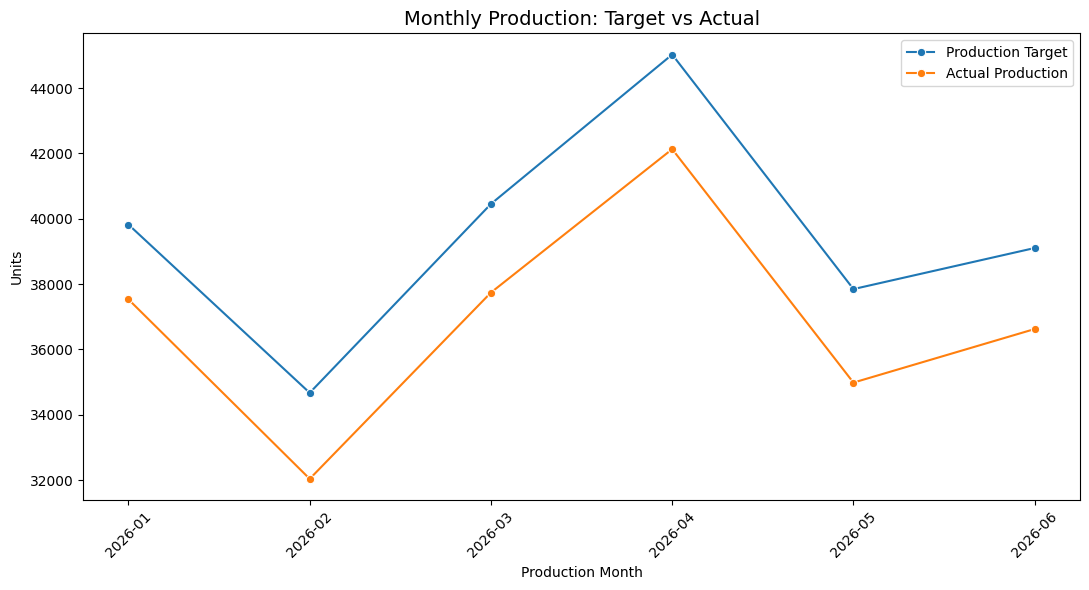

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare monthly trend chart
monthly_chart = monthly_production.reset_index()

monthly_chart["Production_Month"] = (
    monthly_chart["Production_Month"].astype(str)
)

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=monthly_chart,
    x="Production_Month",
    y="Total_Target",
    marker="o",
    label="Production Target"
)

sns.lineplot(
    data=monthly_chart,
    x="Production_Month",
    y="Total_Actual",
    marker="o",
    label="Actual Production"
)

plt.title("Monthly Production: Target vs Actual", fontsize=14)
plt.xlabel("Production Month")
plt.ylabel("Units")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(
    "../outputs/figures/monthly_production_target_vs_actual.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

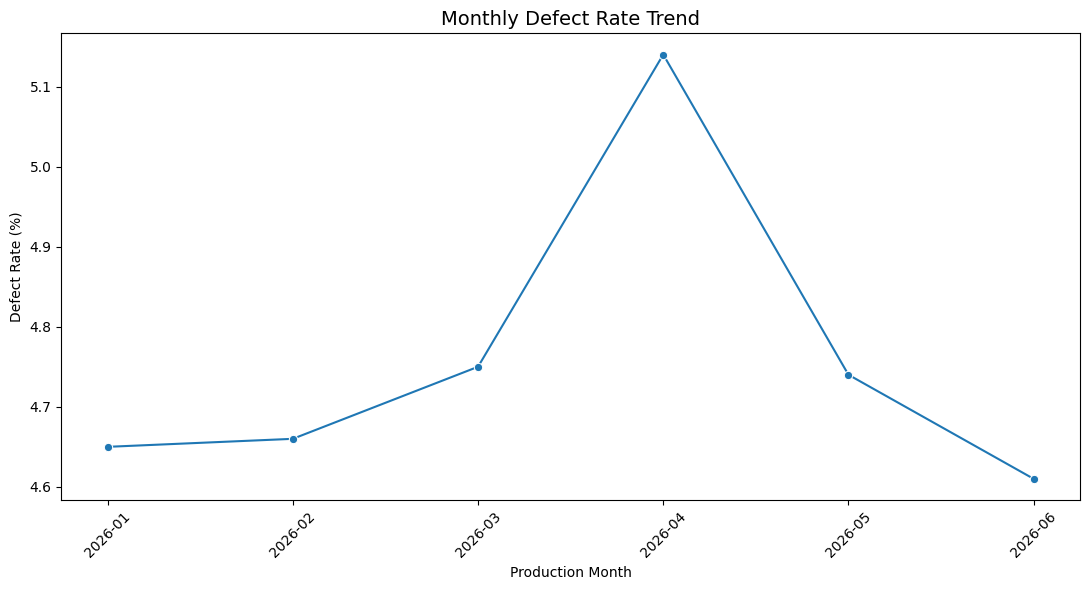

In [10]:
# Monthly defect rate trend

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=monthly_chart,
    x="Production_Month",
    y="Defect_Rate_%",
    marker="o"
)

plt.title("Monthly Defect Rate Trend", fontsize=14)
plt.xlabel("Production Month")
plt.ylabel("Defect Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/monthly_defect_rate_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [1]:
# Department-wise defect rate comparison

department_defects = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

department_defects["Defect_Rate_%"] = (
    department_defects["Total_Defects"]
    / department_defects["Total_Production"] * 100
).round(2)

department_defects = department_defects.sort_values(
    "Defect_Rate_%",
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=department_defects.reset_index(),
    x="Defect_Rate_%",
    y="Department"
)

plt.title("Department-wise Defect Rate Comparison", fontsize=14)
plt.xlabel("Defect Rate (%)")
plt.ylabel("Department")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/department_defect_rate_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(department_defects)

NameError: name 'df' is not defined

In [2]:
import pandas as pd

file_path = "../data/raw/manufacturing_clean_data.csv"

df = pd.read_csv(file_path)

date_columns = [
    "Production_Date",
    "Due_Date",
    "Actual_Delivery_Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        format="%d-%b-%y"
    )

df["Department"] = df["Department"].replace({
    "composite": "Composite"
})

df["Shift"] = df["Shift"].replace({
    "day": "Day"
})

df["Delivery_Delay_Days"] = (
    df["Actual_Delivery_Date"] - df["Due_Date"]
).dt.days

df["Delivery_Status"] = df["Delivery_Delay_Days"].apply(
    lambda days: "Late" if days > 0 else "On Time"
)

print("Dataset restored successfully!")
print("Shape:", df.shape)

Dataset restored successfully!
Shape: (1195, 21)


In [3]:
# Department-wise defect rate comparison

department_defects = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

department_defects["Defect_Rate_%"] = (
    department_defects["Total_Defects"]
    / department_defects["Total_Production"] * 100
).round(2)

department_defects = department_defects.sort_values(
    "Defect_Rate_%",
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=department_defects.reset_index(),
    x="Defect_Rate_%",
    y="Department"
)

plt.title("Department-wise Defect Rate Comparison", fontsize=14)
plt.xlabel("Defect Rate (%)")
plt.ylabel("Department")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/department_defect_rate_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(department_defects)

NameError: name 'plt' is not defined

In [4]:
# Department-wise defect rate comparison

department_defects = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

department_defects["Defect_Rate_%"] = (
    department_defects["Total_Defects"]
    / department_defects["Total_Production"] * 100
).round(2)

department_defects = department_defects.sort_values(
    "Defect_Rate_%",
    ascending=False
)

display(department_defects)

,Total_Production,Total_Defects,Defect_Rate_%
Department,,,
Composite,56256,2806,4.99
Machining,23091,1112,4.82
Spares & Repairs,32773,1561,4.76
Sheet Metal,30708,1456,4.74
Assembly,51256,2389,4.66
Surface Treatment,26976,1218,4.52


In [1]:
# Department-wise defect rate comparison

department_defects = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

department_defects["Defect_Rate_%"] = (
    department_defects["Total_Defects"]
    / department_defects["Total_Production"] * 100
).round(2)

department_defects = department_defects.sort_values(
    "Defect_Rate_%",
    ascending=False
)

display(department_defects)

NameError: name 'df' is not defined

In [2]:
import pandas as pd

file_path = "../data/raw/manufacturing_clean_data.csv"

df = pd.read_csv(file_path)

date_columns = [
    "Production_Date",
    "Due_Date",
    "Actual_Delivery_Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        format="%d-%b-%y"
    )

df["Department"] = df["Department"].replace({
    "composite": "Composite"
})

df["Shift"] = df["Shift"].replace({
    "day": "Day"
})

df["Delivery_Delay_Days"] = (
    df["Actual_Delivery_Date"] - df["Due_Date"]
).dt.days

df["Delivery_Status"] = df["Delivery_Delay_Days"].apply(
    lambda days: "Late" if days > 0 else "On Time"
)

print("Dataset restored successfully!")
print("Shape:", df.shape)

Dataset restored successfully!
Shape: (1195, 21)


In [3]:
# Department-wise defect rate comparison

department_defects = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

department_defects["Defect_Rate_%"] = (
    department_defects["Total_Defects"]
    / department_defects["Total_Production"] * 100
).round(2)

department_defects = department_defects.sort_values(
    "Defect_Rate_%",
    ascending=False
)

display(department_defects)

,Total_Production,Total_Defects,Defect_Rate_%
Department,,,
Composite,56256,2806,4.99
Machining,23091,1112,4.82
Spares & Repairs,32773,1561,4.76
Sheet Metal,30708,1456,4.74
Assembly,51256,2389,4.66
Surface Treatment,26976,1218,4.52


In [4]:
# Department-wise defect rate chart

department_chart = department_defects.reset_index()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=department_chart,
    x="Defect_Rate_%",
    y="Department"
)

plt.title("Department-wise Defect Rate Comparison", fontsize=14)
plt.xlabel("Defect Rate (%)")
plt.ylabel("Department")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/department_defect_rate_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'plt' is not defined

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
print("df exists:", "df" in globals())
print("department_defects exists:", "department_defects" in globals())

df exists: True
department_defects exists: True


In [7]:

# Recovery Code 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")


Libraries imported successfully!


In [8]:

# Recovery Code 2: Restore Dataset

import pandas as pd
from pathlib import Path

file_path = Path("../data/raw/manufacturing_clean_data.csv")

df = pd.read_csv(file_path)

date_columns = [
    "Production_Date",
    "Due_Date",
    "Actual_Delivery_Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        format="%d-%b-%y",
        errors="coerce"
    )

df["Department"] = df["Department"].replace({
    "composite": "Composite"
})

df["Shift"] = df["Shift"].replace({
    "day": "Day"
})

df["Delivery_Delay_Days"] = (
    df["Actual_Delivery_Date"] - df["Due_Date"]
).dt.days

df["Delivery_Status"] = df["Delivery_Delay_Days"].apply(
    lambda days: (
        "Late" if days > 0 else
        "On Time" if pd.notna(days) else
        "Unknown"
    )
)

print("Dataset restored successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset restored successfully!
Dataset shape: (1195, 21)


,Production_ID,Production_Date,Product,Department,Machine,Operator_ID,Shift,Production_Target,Actual_Production,Defects,...,Material_Cost,Labour_Hours,Labour_Cost,Order_Quantity,Due_Date,Actual_Delivery_Date,Quality_Status,Customer,Delivery_Delay_Days,Delivery_Status
0,PRD-00001,2026-06-13,Composite Panel B,Composite,Autoclave-01,OP-008,Night,269,225,5,...,85638.51,4.52,108.48,237,2026-06-15,2026-06-14,Passed,Precision Air,-1,On Time
1,PRD-00002,2026-01-07,Machined Housing,Machining,CNC-04,OP-007,Evening,246,251,10,...,58016.75,9.09,181.80,314,2026-01-14,2026-01-14,Passed,AeroTech UK,0,On Time
2,PRD-00003,2026-01-24,Repair Component,Spares & Repairs,Repair-01,OP-029,Evening,171,185,10,...,18621.51,7.65,183.60,151,2026-02-03,2026-02-03,Rejected,Precision Air,0,On Time
3,PRD-00004,2026-02-19,Composite Panel B,Composite,Autoclave-01,OP-022,Evening,249,203,6,...,53070.63,5.01,110.22,250,2026-02-26,2026-02-27,Passed,AeroTech UK,1,Late
4,PRD-00005,2026-06-05,Sheet Metal Bracket,Sheet Metal,Bender-01,OP-013,Evening,266,219,10,...,31161.32,5.10,112.20,240,2026-06-10,2026-06-08,Passed,AeroTech UK,-2,On Time


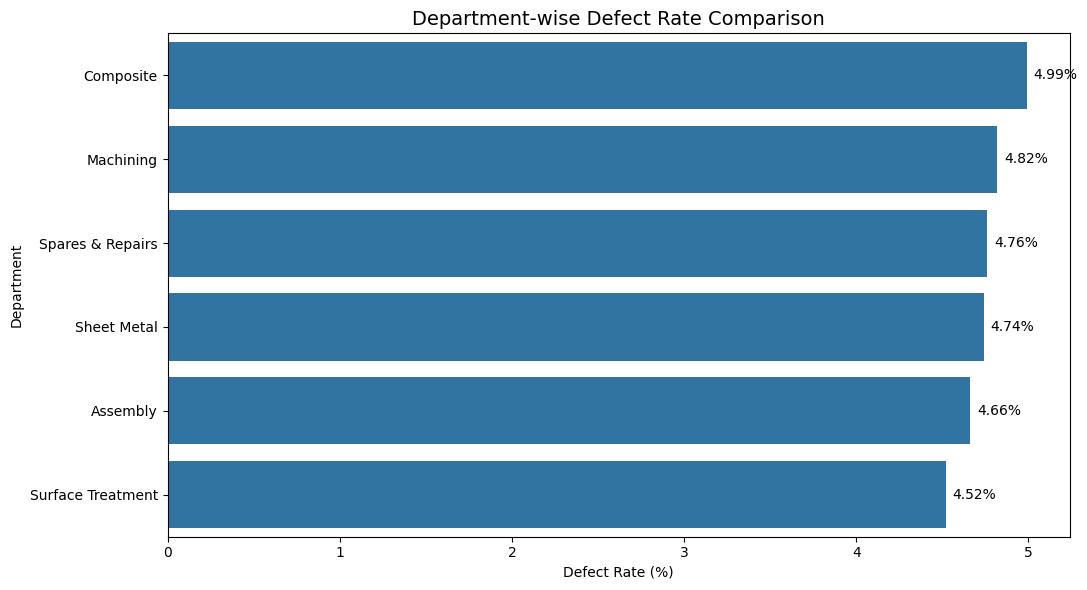

Chart saved successfully!
Saved to: E:\Documents\Data-Analysis-Projects\Manufacturing-Production-Python-Analysis\outputs\figures\department_defect_rate_comparison.png


In [9]:

# Department-wise Defect Rate Comparison Chart

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Recreate the analysis if it is missing
if "department_defects" not in globals():
    department_defects = (
        df.groupby("Department")
        .agg(
            Total_Production=("Actual_Production", "sum"),
            Total_Defects=("Defects", "sum")
        )
    )

    department_defects["Defect_Rate_%"] = (
        department_defects["Total_Defects"]
        / department_defects["Total_Production"] * 100
    ).round(2)

    department_defects = department_defects.sort_values(
        "Defect_Rate_%",
        ascending=False
    )

# Prepare chart data
department_chart = department_defects.reset_index()

# Create output folder if needed
figures_folder = Path("../outputs/figures")
figures_folder.mkdir(parents=True, exist_ok=True)

# Draw chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=department_chart,
    x="Defect_Rate_%",
    y="Department"
)

# Add values to bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Department-wise Defect Rate Comparison", fontsize=14)
plt.xlabel("Defect Rate (%)")
plt.ylabel("Department")
plt.tight_layout()

# Save chart
plt.savefig(
    figures_folder / "department_defect_rate_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")
print("Saved to:", (figures_folder / "department_defect_rate_comparison.png").resolve())


In [10]:

# Department-wise Production Achievement Analysis

department_performance = (
    df.groupby("Department")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Total_Downtime=("Downtime_Hours", "sum")
    )
)

department_performance["Achievement_%"] = (
    department_performance["Total_Actual"]
    / department_performance["Total_Target"] * 100
).round(2)

department_performance = department_performance.sort_values(
    "Achievement_%",
    ascending=False
)

display(department_performance)


,Total_Target,Total_Actual,Total_Defects,Total_Downtime,Achievement_%
Department,,,,,
Sheet Metal,32748,30708,1456,709.7,93.77
Spares & Repairs,34951,32773,1561,761.1,93.77
Assembly,54726,51256,2389,1227.0,93.66
Composite,60199,56256,2806,1304.9,93.45
Surface Treatment,29224,26976,1218,648.1,92.31
Machining,25078,23091,1112,611.3,92.08


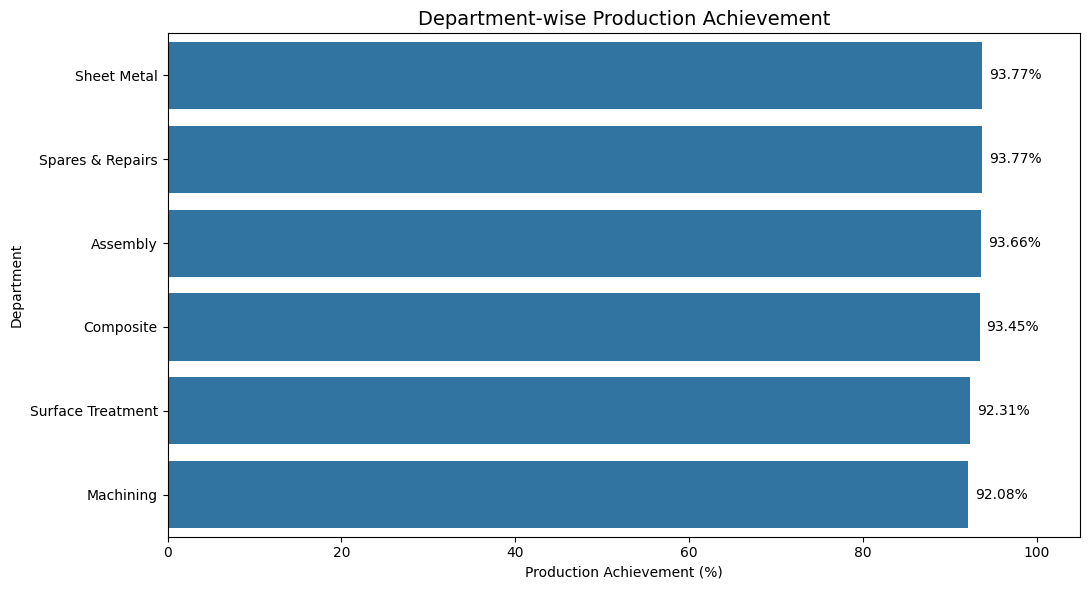

Chart saved successfully!
Saved to: E:\Documents\Data-Analysis-Projects\Manufacturing-Production-Python-Analysis\outputs\figures\department_production_achievement.png


In [11]:

# Department-wise Production Achievement Chart

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Recreate analysis if needed
if "department_performance" not in globals():
    department_performance = (
        df.groupby("Department")
        .agg(
            Total_Target=("Production_Target", "sum"),
            Total_Actual=("Actual_Production", "sum"),
            Total_Defects=("Defects", "sum"),
            Total_Downtime=("Downtime_Hours", "sum")
        )
    )

    department_performance["Achievement_%"] = (
        department_performance["Total_Actual"]
        / department_performance["Total_Target"] * 100
    ).round(2)

    department_performance = department_performance.sort_values(
        "Achievement_%",
        ascending=False
    )

# Prepare chart data
achievement_chart = department_performance.reset_index()

# Create output folder
figures_folder = Path("../outputs/figures")
figures_folder.mkdir(parents=True, exist_ok=True)

# Draw chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=achievement_chart,
    x="Achievement_%",
    y="Department"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title(
    "Department-wise Production Achievement",
    fontsize=14
)
plt.xlabel("Production Achievement (%)")
plt.ylabel("Department")
plt.xlim(0, 105)
plt.tight_layout()

# Save chart
plt.savefig(
    figures_folder / "department_production_achievement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")
print(
    "Saved to:",
    (figures_folder / "department_production_achievement.png").resolve()
)


In [12]:

# Shift-wise Production Performance Analysis

shift_performance = (
    df.groupby("Shift")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Total_Downtime=("Downtime_Hours", "sum")
    )
)

shift_performance["Achievement_%"] = (
    shift_performance["Total_Actual"]
    / shift_performance["Total_Target"] * 100
).round(2)

shift_performance = shift_performance.sort_values(
    "Achievement_%",
    ascending=False
)

display(shift_performance)


,Total_Target,Total_Actual,Total_Defects,Total_Downtime,Achievement_%
Shift,,,,,
Evening,77425,72521,3226,1719.2,93.67
Day,76713,71661,3489,1715.4,93.41
Night,82788,76878,3827,1827.5,92.86


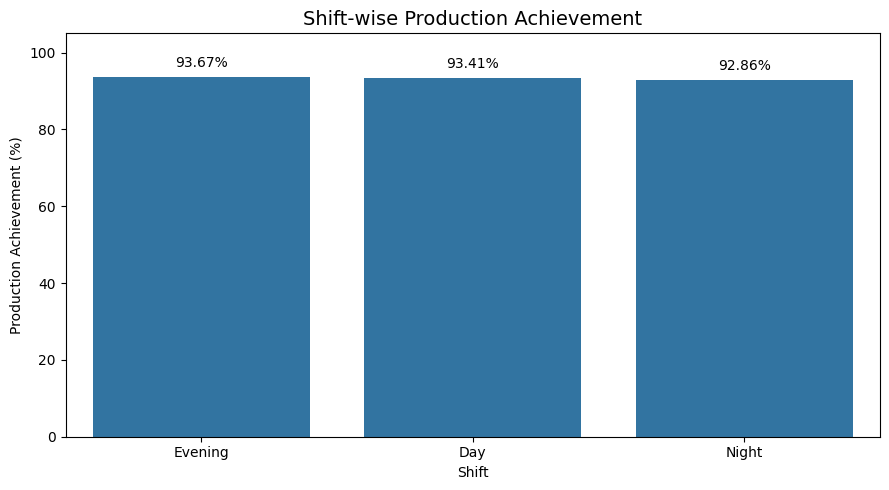

Chart saved successfully!
Saved to: E:\Documents\Data-Analysis-Projects\Manufacturing-Production-Python-Analysis\outputs\figures\shift_production_achievement.png


In [13]:

# Shift-wise Production Achievement Chart

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Recreate analysis if it is missing
if "shift_performance" not in globals():
    shift_performance = (
        df.groupby("Shift")
        .agg(
            Total_Target=("Production_Target", "sum"),
            Total_Actual=("Actual_Production", "sum"),
            Total_Defects=("Defects", "sum"),
            Total_Downtime=("Downtime_Hours", "sum")
        )
    )

    shift_performance["Achievement_%"] = (
        shift_performance["Total_Actual"]
        / shift_performance["Total_Target"] * 100
    ).round(2)

    shift_performance = shift_performance.sort_values(
        "Achievement_%",
        ascending=False
    )

# Prepare chart data
shift_chart = shift_performance.reset_index()

# Create output folder
figures_folder = Path("../outputs/figures")
figures_folder.mkdir(parents=True, exist_ok=True)

# Draw chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=shift_chart,
    x="Shift",
    y="Achievement_%"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Shift-wise Production Achievement", fontsize=14)
plt.xlabel("Shift")
plt.ylabel("Production Achievement (%)")
plt.ylim(0, 105)
plt.tight_layout()

# Save chart
plt.savefig(
    figures_folder / "shift_production_achievement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")
print(
    "Saved to:",
    (figures_folder / "shift_production_achievement.png").resolve()
)


In [2]:
# Shift-wise Defect Rate Analysis

shift_defects = (
    df.groupby("Shift")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

shift_defects["Defect_Rate_%"] = (
    shift_defects["Total_Defects"]
    / shift_defects["Total_Production"] * 100
).round(2)

shift_defects = shift_defects.sort_values(
    "Defect_Rate_%",
    ascending=False
)

display(shift_defects)

NameError: name 'df' is not defined

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/raw/manufacturing_clean_data.csv")

df = pd.read_csv(file_path)

date_columns = [
    "Production_Date",
    "Due_Date",
    "Actual_Delivery_Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        format="%d-%b-%y",
        errors="coerce"
    )

df["Department"] = df["Department"].replace({
    "composite": "Composite"
})

df["Shift"] = df["Shift"].replace({
    "day": "Day"
})

df["Delivery_Delay_Days"] = (
    df["Actual_Delivery_Date"] - df["Due_Date"]
).dt.days

df["Delivery_Status"] = df["Delivery_Delay_Days"].apply(
    lambda days: (
        "Late" if days > 0 else
        "On Time" if pd.notna(days) else
        "Unknown"
    )
)

print("Dataset restored successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset restored successfully!
Dataset shape: (1195, 21)


,Production_ID,Production_Date,Product,Department,Machine,Operator_ID,Shift,Production_Target,Actual_Production,Defects,...,Material_Cost,Labour_Hours,Labour_Cost,Order_Quantity,Due_Date,Actual_Delivery_Date,Quality_Status,Customer,Delivery_Delay_Days,Delivery_Status
0,PRD-00001,2026-06-13,Composite Panel B,Composite,Autoclave-01,OP-008,Night,269,225,5,...,85638.51,4.52,108.48,237,2026-06-15,2026-06-14,Passed,Precision Air,-1,On Time
1,PRD-00002,2026-01-07,Machined Housing,Machining,CNC-04,OP-007,Evening,246,251,10,...,58016.75,9.09,181.80,314,2026-01-14,2026-01-14,Passed,AeroTech UK,0,On Time
2,PRD-00003,2026-01-24,Repair Component,Spares & Repairs,Repair-01,OP-029,Evening,171,185,10,...,18621.51,7.65,183.60,151,2026-02-03,2026-02-03,Rejected,Precision Air,0,On Time
3,PRD-00004,2026-02-19,Composite Panel B,Composite,Autoclave-01,OP-022,Evening,249,203,6,...,53070.63,5.01,110.22,250,2026-02-26,2026-02-27,Passed,AeroTech UK,1,Late
4,PRD-00005,2026-06-05,Sheet Metal Bracket,Sheet Metal,Bender-01,OP-013,Evening,266,219,10,...,31161.32,5.10,112.20,240,2026-06-10,2026-06-08,Passed,AeroTech UK,-2,On Time


In [5]:
# Shift-wise Defect Rate Analysis

shift_defects = (
    df.groupby("Shift")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

shift_defects["Defect_Rate_%"] = (
    shift_defects["Total_Defects"]
    / shift_defects["Total_Production"] * 100
).round(2)

shift_defects = shift_defects.sort_values(
    "Defect_Rate_%",
    ascending=False
)

display(shift_defects)

,Total_Production,Total_Defects,Defect_Rate_%
Shift,,,
Night,76878,3827,4.98
Day,71661,3489,4.87
Evening,72521,3226,4.45


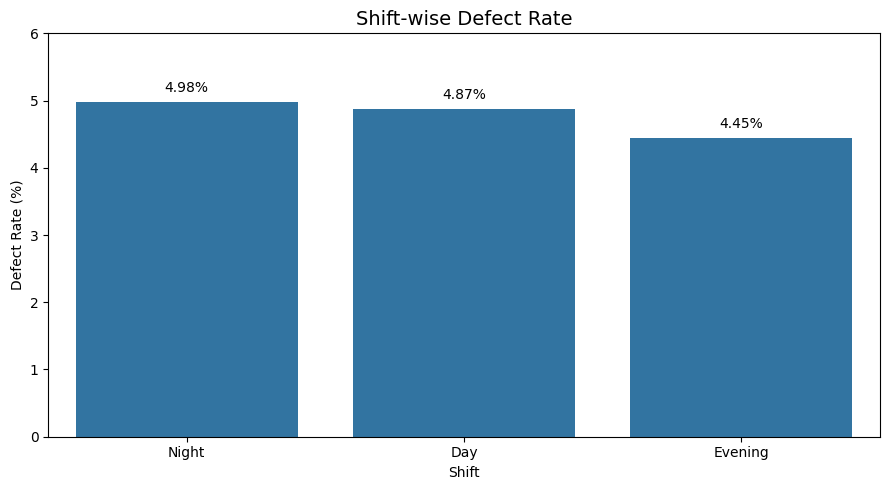

Chart saved successfully!
Saved to: E:\Documents\Data-Analysis-Projects\Manufacturing-Production-Python-Analysis\outputs\figures\shift_defect_rate.png


In [6]:
# Shift-wise Defect Rate Chart

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Recreate analysis if it is missing
if "shift_defects" not in globals():
    shift_defects = (
        df.groupby("Shift")
        .agg(
            Total_Production=("Actual_Production", "sum"),
            Total_Defects=("Defects", "sum")
        )
    )

    shift_defects["Defect_Rate_%"] = (
        shift_defects["Total_Defects"]
        / shift_defects["Total_Production"] * 100
    ).round(2)

    shift_defects = shift_defects.sort_values(
        "Defect_Rate_%",
        ascending=False
    )

# Prepare chart data
shift_defect_chart = shift_defects.reset_index()

# Create output folder
figures_folder = Path("../outputs/figures")
figures_folder.mkdir(parents=True, exist_ok=True)

# Draw chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=shift_defect_chart,
    x="Shift",
    y="Defect_Rate_%"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Shift-wise Defect Rate", fontsize=14)
plt.xlabel("Shift")
plt.ylabel("Defect Rate (%)")
plt.ylim(0, 6)
plt.tight_layout()

# Save chart
plt.savefig(
    figures_folder / "shift_defect_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")
print(
    "Saved to:",
    (figures_folder / "shift_defect_rate.png").resolve()
)

In [7]:
# Product-wise Production Performance Analysis

product_performance = (
    df.groupby("Product")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

product_performance["Achievement_%"] = (
    product_performance["Total_Actual"]
    / product_performance["Total_Target"] * 100
).round(2)

product_performance = product_performance.sort_values(
    "Achievement_%",
    ascending=False
)

display(product_performance)

,Total_Target,Total_Actual,Total_Defects,Achievement_%
Product,,,,
Assembly Kit Y,27519,26054,1312,94.68
Composite Panel A,26739,25288,1268,94.57
Repair Component,34951,32773,1561,93.77
Sheet Metal Bracket,32748,30708,1456,93.77
Assembly Kit X,27207,25202,1077,92.63
Composite Panel B,33460,30968,1538,92.55
Surface Treatment Part,29224,26976,1218,92.31
Machined Housing,25078,23091,1112,92.08


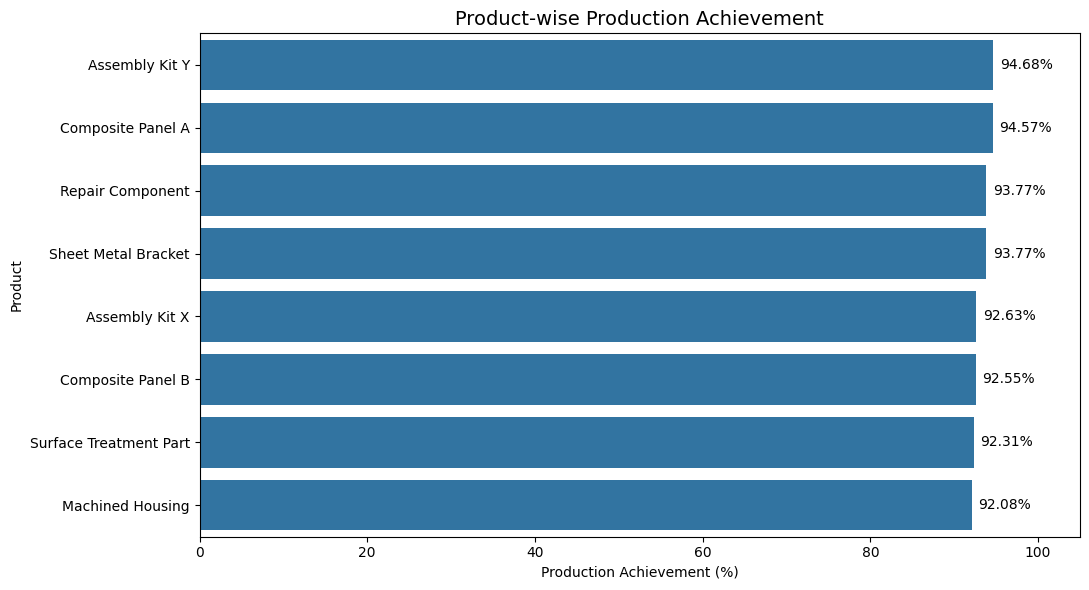

Chart saved successfully!
Saved to: E:\Documents\Data-Analysis-Projects\Manufacturing-Production-Python-Analysis\outputs\figures\product_production_achievement.png


In [8]:
# Product-wise Production Achievement Chart

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Recreate analysis if it is missing
if "product_performance" not in globals():
    product_performance = (
        df.groupby("Product")
        .agg(
            Total_Target=("Production_Target", "sum"),
            Total_Actual=("Actual_Production", "sum"),
            Total_Defects=("Defects", "sum")
        )
    )

    product_performance["Achievement_%"] = (
        product_performance["Total_Actual"]
        / product_performance["Total_Target"] * 100
    ).round(2)

    product_performance = product_performance.sort_values(
        "Achievement_%",
        ascending=False
    )

# Prepare chart data
product_chart = product_performance.reset_index()

# Create output folder
figures_folder = Path("../outputs/figures")
figures_folder.mkdir(parents=True, exist_ok=True)

# Draw chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=product_chart,
    x="Achievement_%",
    y="Product"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title(
    "Product-wise Production Achievement",
    fontsize=14
)
plt.xlabel("Production Achievement (%)")
plt.ylabel("Product")
plt.xlim(0, 105)
plt.tight_layout()

# Save chart
plt.savefig(
    figures_folder / "product_production_achievement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")
print(
    "Saved to:",
    (figures_folder / "product_production_achievement.png").resolve()
)

In [9]:
# Overall Delivery Performance

delivery_summary = (
    df["Delivery_Status"]
    .value_counts()
    .rename_axis("Delivery_Status")
    .reset_index(name="Count")
)

delivery_summary["Percentage_%"] = (
    delivery_summary["Count"]
    / delivery_summary["Count"].sum() * 100
).round(2)

display(delivery_summary)

,Delivery_Status,Count,Percentage_%
0,On Time,738,61.76
1,Late,457,38.24


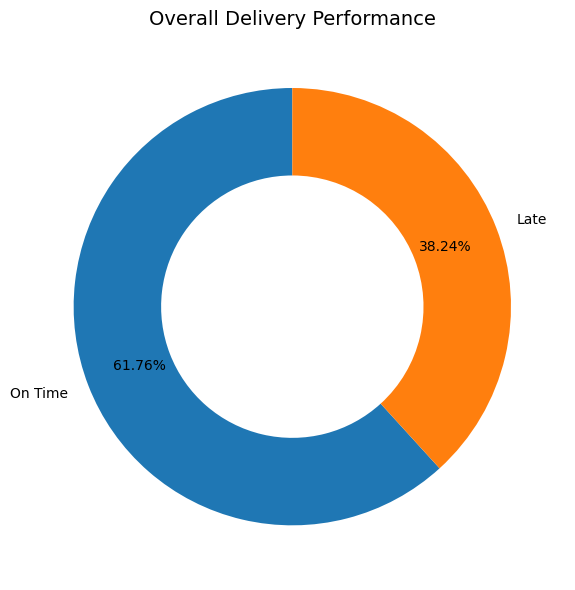

Chart saved successfully!
Saved to: E:\Documents\Data-Analysis-Projects\Manufacturing-Production-Python-Analysis\outputs\figures\overall_delivery_performance.png


In [10]:

# Overall Delivery Performance Donut Chart

import matplotlib.pyplot as plt
from pathlib import Path

# Recreate summary if missing
if "delivery_summary" not in globals():
    delivery_summary = (
        df["Delivery_Status"]
        .value_counts()
        .rename_axis("Delivery_Status")
        .reset_index(name="Count")
    )

    delivery_summary["Percentage_%"] = (
        delivery_summary["Count"]
        / delivery_summary["Count"].sum() * 100
    ).round(2)

# Prepare chart data
labels = delivery_summary["Delivery_Status"]
values = delivery_summary["Count"]

# Create output folder
figures_folder = Path("../outputs/figures")
figures_folder.mkdir(parents=True, exist_ok=True)

# Draw donut chart
plt.figure(figsize=(8, 6))

plt.pie(
    values,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={"width": 0.4},
    pctdistance=0.75
)

plt.title("Overall Delivery Performance", fontsize=14)
plt.tight_layout()

# Save chart
plt.savefig(
    figures_folder / "overall_delivery_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")
print(
    "Saved to:",
    (figures_folder / "overall_delivery_performance.png").resolve()
)


In [11]:
# Department-wise Delivery Performance Analysis

department_delivery = (
    df.groupby("Department")
    .agg(
        Total_Deliveries=("Delivery_Status", "count"),
        Late_Deliveries=(
            "Delivery_Status",
            lambda x: (x == "Late").sum()
        ),
        On_Time_Deliveries=(
            "Delivery_Status",
            lambda x: (x == "On Time").sum()
        )
    )
)

department_delivery["Late_Rate_%"] = (
    department_delivery["Late_Deliveries"]
    / department_delivery["Total_Deliveries"] * 100
).round(2)

department_delivery = department_delivery.sort_values(
    "Late_Rate_%",
    ascending=False
)

display(department_delivery)

,Total_Deliveries,Late_Deliveries,On_Time_Deliveries,Late_Rate_%
Department,,,,
Machining,129,54,75,41.86
Surface Treatment,148,60,88,40.54
Assembly,273,103,170,37.73
Sheet Metal,167,63,104,37.72
Composite,302,113,189,37.42
Spares & Repairs,176,64,112,36.36


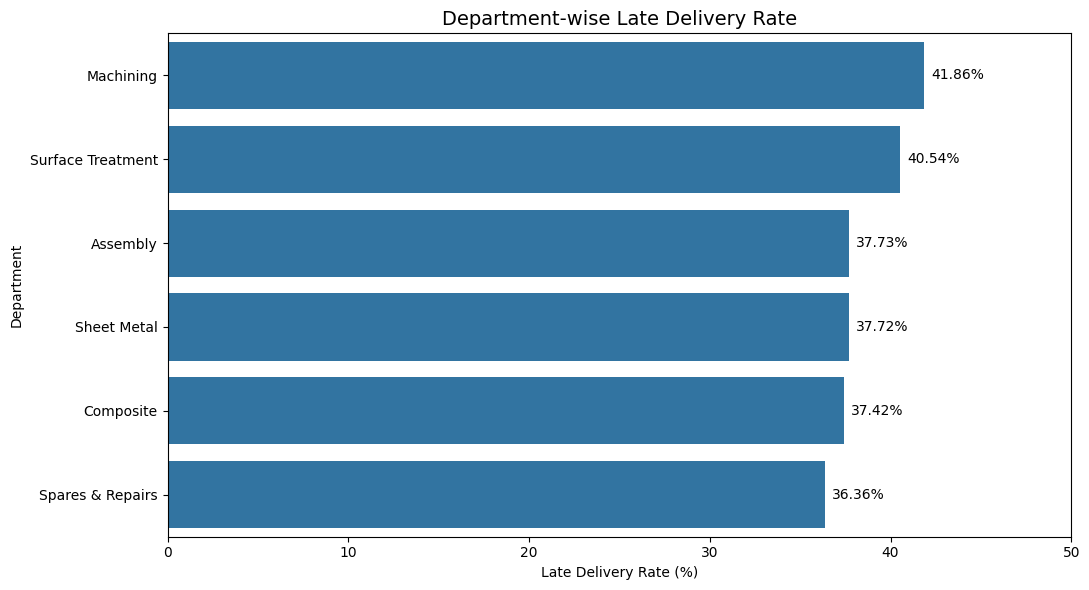

Chart saved successfully!
Saved to: E:\Documents\Data-Analysis-Projects\Manufacturing-Production-Python-Analysis\outputs\figures\department_late_delivery_rate.png


In [12]:

# Department-wise Late Delivery Rate Chart

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Recreate analysis if missing
if "department_delivery" not in globals():
    department_delivery = (
        df.groupby("Department")
        .agg(
            Total_Deliveries=("Delivery_Status", "count"),
            Late_Deliveries=(
                "Delivery_Status",
                lambda x: (x == "Late").sum()
            ),
            On_Time_Deliveries=(
                "Delivery_Status",
                lambda x: (x == "On Time").sum()
            )
        )
    )

    department_delivery["Late_Rate_%"] = (
        department_delivery["Late_Deliveries"]
        / department_delivery["Total_Deliveries"] * 100
    ).round(2)

    department_delivery = department_delivery.sort_values(
        "Late_Rate_%",
        ascending=False
    )

# Prepare chart data
delivery_chart = department_delivery.reset_index()

# Create output folder
figures_folder = Path("../outputs/figures")
figures_folder.mkdir(parents=True, exist_ok=True)

# Draw chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=delivery_chart,
    x="Late_Rate_%",
    y="Department"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=5)

plt.title("Department-wise Late Delivery Rate", fontsize=14)
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Department")
plt.xlim(0, 50)
plt.tight_layout()

# Save chart
plt.savefig(
    figures_folder / "department_late_delivery_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")
print(
    "Saved to:",
    (figures_folder / "department_late_delivery_rate.png").resolve()
)


In [13]:
# Department-wise Average Delivery Delay Analysis

late_delivery_analysis = (
    df[df["Delivery_Status"] == "Late"]
    .groupby("Department")
    .agg(
        Late_Deliveries=("Delivery_Status", "count"),
        Average_Delay_Days=("Delivery_Delay_Days", "mean"),
        Maximum_Delay_Days=("Delivery_Delay_Days", "max")
    )
)

late_delivery_analysis["Average_Delay_Days"] = (
    late_delivery_analysis["Average_Delay_Days"].round(2)
)

late_delivery_analysis = late_delivery_analysis.sort_values(
    "Average_Delay_Days",
    ascending=False
)

display(late_delivery_analysis)

,Late_Deliveries,Average_Delay_Days,Maximum_Delay_Days
Department,,,
Sheet Metal,63,2.62,4
Machining,54,2.59,4
Composite,113,2.45,4
Surface Treatment,60,2.30,4
Assembly,103,2.24,4
Spares & Repairs,64,2.08,4


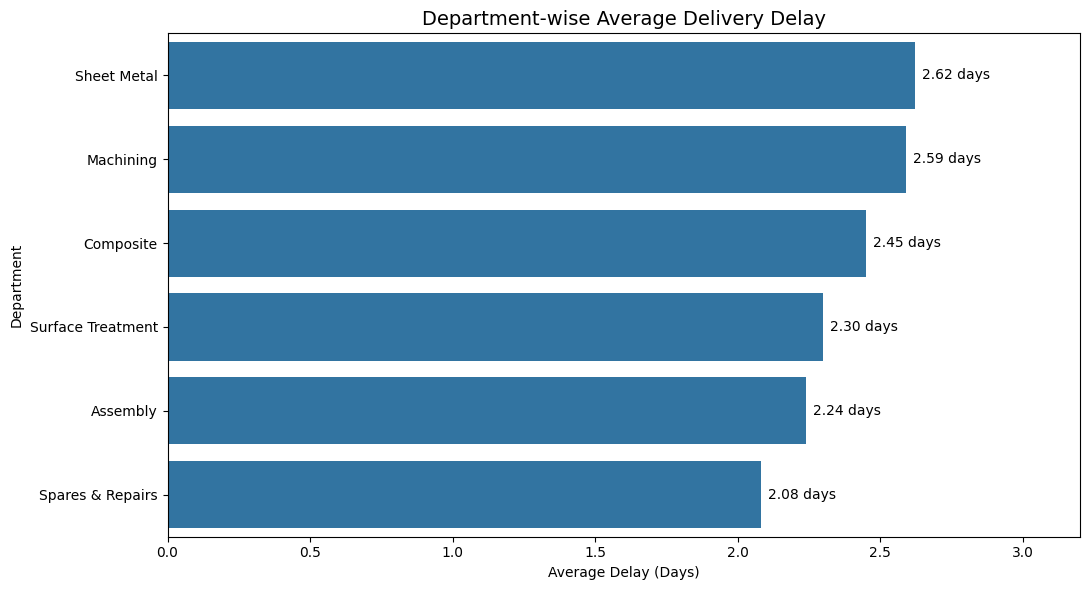

Chart saved successfully!
Saved to: E:\Documents\Data-Analysis-Projects\Manufacturing-Production-Python-Analysis\outputs\figures\department_average_delivery_delay.png


In [14]:

# Department-wise Average Delivery Delay Chart

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Recreate analysis if missing
if "late_delivery_analysis" not in globals():
    late_delivery_analysis = (
        df[df["Delivery_Status"] == "Late"]
        .groupby("Department")
        .agg(
            Late_Deliveries=("Delivery_Status", "count"),
            Average_Delay_Days=("Delivery_Delay_Days", "mean"),
            Maximum_Delay_Days=("Delivery_Delay_Days", "max")
        )
    )

    late_delivery_analysis["Average_Delay_Days"] = (
        late_delivery_analysis["Average_Delay_Days"].round(2)
    )

    late_delivery_analysis = late_delivery_analysis.sort_values(
        "Average_Delay_Days",
        ascending=False
    )

# Prepare chart data
delay_chart = late_delivery_analysis.reset_index()

# Create output folder
figures_folder = Path("../outputs/figures")
figures_folder.mkdir(parents=True, exist_ok=True)

# Draw chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=delay_chart,
    x="Average_Delay_Days",
    y="Department"
)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f days", padding=5)

plt.title("Department-wise Average Delivery Delay", fontsize=14)
plt.xlabel("Average Delay (Days)")
plt.ylabel("Department")
plt.xlim(0, 3.2)
plt.tight_layout()

# Save chart
plt.savefig(
    figures_folder / "department_average_delivery_delay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")
print(
    "Saved to:",
    (figures_folder / "department_average_delivery_delay.png").resolve()
)


In [15]:
from pathlib import Path

# Chart folder location
figures_folder = Path("../outputs/figures")

# Find all saved PNG charts
chart_files = sorted(figures_folder.glob("*.png"))

print("Total Charts Created:", len(chart_files))
print("\nList of Saved Charts:\n")

for number, chart in enumerate(chart_files, start=1):
    print(f"{number}. {chart.name}")

Total Charts Created: 10

List of Saved Charts:

1. department_average_delivery_delay.png
2. department_defect_rate_comparison.png
3. department_late_delivery_rate.png
4. department_production_achievement.png
5. monthly_defect_rate_trend.png
6. monthly_production_target_vs_actual.png
7. overall_delivery_performance.png
8. product_production_achievement.png
9. shift_defect_rate.png
10. shift_production_achievement.png


In [16]:
# Check important analysis variables

analysis_variables = [
    "monthly_production",
    "department_defects",
    "shift_analysis",
    "product_analysis",
    "quality_analysis",
    "delivery_analysis",
    "late_delivery_analysis"
]

print("ANALYSIS AUDIT\n")

for variable in analysis_variables:
    if variable in globals():
        print(f"✓ {variable}: Available")
    else:
        print(f"✗ {variable}: Not Available")

ANALYSIS AUDIT

✗ monthly_production: Not Available
✗ department_defects: Not Available
✗ shift_analysis: Not Available
✗ product_analysis: Not Available
✗ quality_analysis: Not Available
✗ delivery_analysis: Not Available
✓ late_delivery_analysis: Available


In [17]:
# Monthly Production Analysis

df["Production_Month"] = df["Production_Date"].dt.to_period("M")

monthly_production = (
    df.groupby("Production_Month")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Total_Downtime=("Downtime_Hours", "sum"),
        Total_Records=("Production_ID", "count")
    )
)

monthly_production["Achievement_%"] = (
    monthly_production["Total_Actual"]
    / monthly_production["Total_Target"] * 100
).round(2)

monthly_production["Defect_Rate_%"] = (
    monthly_production["Total_Defects"]
    / monthly_production["Total_Actual"] * 100
).round(2)

display(monthly_production)

,Total_Target,Total_Actual,Total_Defects,Total_Downtime,Total_Records,Achievement_%,Defect_Rate_%
Production_Month,,,,,,,
2026-01,39822,37533,1745,876.1,207,94.25,4.65
2026-02,34674,32042,1493,767.7,176,92.41,4.66
2026-03,40453,37742,1791,894.7,198,93.30,4.75
2026-04,45024,42130,2165,978.2,226,93.57,5.14
2026-05,37848,34987,1660,873.4,192,92.44,4.74
2026-06,39105,36626,1688,872.0,196,93.66,4.61


In [18]:
# Department-wise Defect Analysis

department_defects = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Average_Defects=("Defects", "mean"),
        Rejected=("Quality_Status", lambda x: (x == "Rejected").sum()),
        Rework=("Quality_Status", lambda x: (x == "Rework").sum())
    )
)

department_defects["Defect_Rate_%"] = (
    department_defects["Total_Defects"]
    / department_defects["Total_Production"] * 100
).round(2)

department_defects["Average_Defects"] = (
    department_defects["Average_Defects"].round(2)
)

department_defects = department_defects.sort_values(
    "Defect_Rate_%", ascending=False
)

display(department_defects)

,Total_Production,Total_Defects,Average_Defects,Rejected,Rework,Defect_Rate_%
Department,,,,,,
Composite,56256,2806,9.29,58,60,4.99
Machining,23091,1112,8.62,23,25,4.82
Spares & Repairs,32773,1561,8.87,34,35,4.76
Sheet Metal,30708,1456,8.72,42,23,4.74
Assembly,51256,2389,8.75,54,51,4.66
Surface Treatment,26976,1218,8.23,32,37,4.52


In [19]:
# Shift-wise Production Analysis

shift_analysis = (
    df.groupby("Shift")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Total_Downtime=("Downtime_Hours", "sum")
    )
)

shift_analysis["Achievement_%"] = (
    shift_analysis["Total_Actual"]
    / shift_analysis["Total_Target"] * 100
).round(2)

shift_analysis["Defect_Rate_%"] = (
    shift_analysis["Total_Defects"]
    / shift_analysis["Total_Actual"] * 100
).round(2)

display(shift_analysis)

,Total_Target,Total_Actual,Total_Defects,Total_Downtime,Achievement_%,Defect_Rate_%
Shift,,,,,,
Day,76713,71661,3489,1715.4,93.41,4.87
Evening,77425,72521,3226,1719.2,93.67,4.45
Night,82788,76878,3827,1827.5,92.86,4.98


In [20]:
# Product-wise Production Analysis

product_analysis = (
    df.groupby("Product")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Total_Downtime=("Downtime_Hours", "sum")
    )
)

product_analysis["Achievement_%"] = (
    product_analysis["Total_Actual"]
    / product_analysis["Total_Target"] * 100
).round(2)

product_analysis["Defect_Rate_%"] = (
    product_analysis["Total_Defects"]
    / product_analysis["Total_Actual"] * 100
).round(2)

product_analysis = product_analysis.sort_values(
    "Achievement_%", ascending=False
)

display(product_analysis)

,Total_Target,Total_Actual,Total_Defects,Total_Downtime,Achievement_%,Defect_Rate_%
Product,,,,,,
Assembly Kit Y,27519,26054,1312,600.7,94.68,5.04
Composite Panel A,26739,25288,1268,608.9,94.57,5.01
Repair Component,34951,32773,1561,761.1,93.77,4.76
Sheet Metal Bracket,32748,30708,1456,709.7,93.77,4.74
Assembly Kit X,27207,25202,1077,626.3,92.63,4.27
Composite Panel B,33460,30968,1538,696.0,92.55,4.97
Surface Treatment Part,29224,26976,1218,648.1,92.31,4.52
Machined Housing,25078,23091,1112,611.3,92.08,4.82


In [21]:
# Quality Status Analysis

quality_analysis = (
    df.groupby(["Department", "Quality_Status"])
    .size()
    .unstack(fill_value=0)
)

quality_analysis["Total_Records"] = quality_analysis.sum(axis=1)

display(quality_analysis)

Quality_Status,Not Recorded,Passed,Rejected,Rework,Total_Records
Department,,,,,
Assembly,2,166,54,51,273
Composite,0,184,58,60,302
Machining,0,81,23,25,129
Sheet Metal,0,102,42,23,167
Spares & Repairs,2,105,34,35,176
Surface Treatment,0,79,32,37,148


In [22]:
# Delivery Performance Analysis

delivery_analysis = (
    df.groupby("Delivery_Status")
    .agg(
        Total_Deliveries=("Production_ID", "count"),
        Average_Delay_Days=("Delivery_Delay_Days", "mean")
    )
)

delivery_analysis["Percentage_%"] = (
    delivery_analysis["Total_Deliveries"]
    / delivery_analysis["Total_Deliveries"].sum() * 100
).round(2)

delivery_analysis["Average_Delay_Days"] = (
    delivery_analysis["Average_Delay_Days"].round(2)
)

display(delivery_analysis)

,Total_Deliveries,Average_Delay_Days,Percentage_%
Delivery_Status,,,
Late,457,2.37,38.24
On Time,738,-0.52,61.76


In [23]:
# Machine-wise Production Performance Analysis

machine_analysis = (
    df.groupby("Machine")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Total_Downtime=("Downtime_Hours", "sum"),
        Total_Records=("Production_ID", "count")
    )
)

machine_analysis["Achievement_%"] = (
    machine_analysis["Total_Actual"]
    / machine_analysis["Total_Target"] * 100
).round(2)

machine_analysis["Defect_Rate_%"] = (
    machine_analysis["Total_Defects"]
    / machine_analysis["Total_Actual"] * 100
).round(2)

machine_analysis = machine_analysis.sort_values(
    "Achievement_%", ascending=False
)

display(machine_analysis)

,Total_Target,Total_Actual,Total_Defects,Total_Downtime,Total_Records,Achievement_%,Defect_Rate_%
Machine,,,,,,,
CNC-01,19726,18723,859,446.1,102,94.92,4.59
Surface-01,13387,12694,544,327.9,68,94.82,4.29
Assembly-01,16828,15952,800,359.8,82,94.79,5.02
Repair-02,15879,15040,705,353.3,80,94.72,4.69
Laser-01,11491,10878,527,275.0,61,94.67,4.84
Bender-01,8139,7655,296,173.6,41,94.05,3.87
Assembly-03,17404,16307,714,384.3,87,93.70,4.38
Autoclave-02,17352,16255,806,393.0,90,93.68,4.96
Repair-01,19072,17733,856,407.8,96,92.98,4.83


In [24]:
# Department-wise Downtime Efficiency Analysis

downtime_analysis = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Downtime=("Downtime_Hours", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

downtime_analysis["Downtime_per_1000_Units"] = (
    downtime_analysis["Total_Downtime"]
    / downtime_analysis["Total_Production"] * 1000
).round(2)

downtime_analysis = downtime_analysis.sort_values(
    "Downtime_per_1000_Units",
    ascending=False
)

display(downtime_analysis)

,Total_Production,Total_Downtime,Total_Defects,Downtime_per_1000_Units
Department,,,,
Machining,23091,611.3,1112,26.47
Surface Treatment,26976,648.1,1218,24.03
Assembly,51256,1227.0,2389,23.94
Spares & Repairs,32773,761.1,1561,23.22
Composite,56256,1304.9,2806,23.20
Sheet Metal,30708,709.7,1456,23.11


In [25]:
# Machine-wise Downtime Efficiency Analysis

machine_downtime = (
    df.groupby("Machine")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Downtime=("Downtime_Hours", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

machine_downtime["Downtime_per_1000_Units"] = (
    machine_downtime["Total_Downtime"]
    / machine_downtime["Total_Production"] * 1000
).round(2)

machine_downtime = machine_downtime.sort_values(
    "Downtime_per_1000_Units",
    ascending=False
)

display(machine_downtime)

,Total_Production,Total_Downtime,Total_Defects,Downtime_per_1000_Units
Machine,,,,
CNC-04,7695,222.6,410,28.93
Surface-01,12694,327.9,544,25.83
CNC-02,9443,240.7,379,25.49
Assembly-02,18997,482.9,875,25.42
Laser-01,10878,275.0,527,25.28
CNC-03,5953,148.0,323,24.86
Autoclave-02,16255,393.0,806,24.18
CNC-01,18723,446.1,859,23.83
Assembly-03,16307,384.3,714,23.57


In [26]:
# Production Target Gap Analysis

target_gap_analysis = (
    df.groupby("Department")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum")
    )
)

target_gap_analysis["Production_Gap"] = (
    target_gap_analysis["Total_Target"]
    - target_gap_analysis["Total_Actual"]
)

target_gap_analysis["Gap_%"] = (
    target_gap_analysis["Production_Gap"]
    / target_gap_analysis["Total_Target"] * 100
).round(2)

target_gap_analysis = target_gap_analysis.sort_values(
    "Production_Gap",
    ascending=False
)

display(target_gap_analysis)

,Total_Target,Total_Actual,Production_Gap,Gap_%
Department,,,,
Composite,60199,56256,3943,6.55
Assembly,54726,51256,3470,6.34
Surface Treatment,29224,26976,2248,7.69
Spares & Repairs,34951,32773,2178,6.23
Sheet Metal,32748,30708,2040,6.23
Machining,25078,23091,1987,7.92


In [27]:
# Operator-wise Performance Analysis

operator_analysis = (
    df.groupby("Operator_ID")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Total_Records=("Production_ID", "count")
    )
)

operator_analysis["Achievement_%"] = (
    operator_analysis["Total_Actual"]
    / operator_analysis["Total_Target"] * 100
).round(2)

operator_analysis["Defect_Rate_%"] = (
    operator_analysis["Total_Defects"]
    / operator_analysis["Total_Actual"] * 100
).round(2)

operator_analysis = operator_analysis.sort_values(
    "Achievement_%",
    ascending=False
)

display(operator_analysis)

,Total_Target,Total_Actual,Total_Defects,Total_Records,Achievement_%,Defect_Rate_%
Operator_ID,,,,,,
OP-017,7308,7130,372,42,97.56,5.22
OP-003,7194,6962,288,39,96.78,4.14
OP-023,13587,13148,649,65,96.77,4.94
OP-029,8884,8529,533,41,96.00,6.25
OP-019,6564,6284,271,33,95.73,4.31
OP-013,8961,8575,398,45,95.69,4.64
OP-018,6520,6196,327,33,95.03,5.28
OP-014,7428,7047,319,39,94.87,4.53
OP-030,5707,5404,248,29,94.69,4.59


In [28]:
# Department-wise Production Cost Analysis

cost_analysis = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Material_Cost=("Material_Cost", "sum"),
        Labour_Cost=("Labour_Cost", "sum")
    )
)

cost_analysis["Total_Cost"] = (
    cost_analysis["Material_Cost"]
    + cost_analysis["Labour_Cost"]
)

cost_analysis["Cost_per_Unit"] = (
    cost_analysis["Total_Cost"]
    / cost_analysis["Total_Production"]
).round(2)

cost_analysis = cost_analysis.sort_values(
    "Cost_per_Unit",
    ascending=False
)

display(cost_analysis)

,Total_Production,Material_Cost,Labour_Cost,Total_Cost,Cost_per_Unit
Department,,,,,
Composite,56256,16884044.23,37443.50,16921487.73,300.79
Machining,23091,5304981.82,15090.34,5320072.16,230.40
Assembly,51256,9557166.07,33925.06,9591091.13,187.12
Surface Treatment,26976,3897762.11,17885.28,3915647.39,145.15
Sheet Metal,30708,3583646.02,20565.26,3604211.28,117.37
Spares & Repairs,32773,3028362.30,22305.26,3050667.56,93.08


In [29]:
# Department-wise Cost Breakdown

cost_analysis["Material_Cost_%"] = (
    cost_analysis["Material_Cost"]
    / cost_analysis["Total_Cost"] * 100
).round(2)

cost_analysis["Labour_Cost_%"] = (
    cost_analysis["Labour_Cost"]
    / cost_analysis["Total_Cost"] * 100
).round(2)

display(
    cost_analysis[
        [
            "Material_Cost_%",
            "Labour_Cost_%"
        ]
    ]
)

,Material_Cost_%,Labour_Cost_%
Department,,
Composite,99.78,0.22
Machining,99.72,0.28
Assembly,99.65,0.35
Surface Treatment,99.54,0.46
Sheet Metal,99.43,0.57
Spares & Repairs,99.27,0.73


In [30]:
# Labour Cost Data Validation

print("Labour Cost Statistics:")
display(df["Labour_Cost"].describe())

print("\nMaterial Cost Statistics:")
display(df["Material_Cost"].describe())

Labour Cost Statistics:


count    1195.000000
mean      123.192218
std        58.619894
min        25.600000
25%        78.780000
50%       111.320000
75%       157.450000
max       366.340000
Name: Labour_Cost, dtype: float64


Material Cost Statistics:


count      1195.000000
mean      35360.638117
std       20970.105767
min        6167.180000
25%       19482.750000
50%       30011.700000
75%       46684.570000
max      132468.120000
Name: Material_Cost, dtype: float64

In [31]:
# Average Cost per Production Record by Department

average_cost_analysis = (
    df.groupby("Department")
    .agg(
        Average_Material_Cost=("Material_Cost", "mean"),
        Average_Labour_Cost=("Labour_Cost", "mean"),
        Average_Production=("Actual_Production", "mean")
    )
)

average_cost_analysis = average_cost_analysis.round(2)

display(average_cost_analysis)

,Average_Material_Cost,Average_Labour_Cost,Average_Production
Department,,,
Assembly,35007.93,124.27,187.75
Composite,55907.43,123.99,186.28
Machining,41123.89,116.98,179.00
Sheet Metal,21458.96,123.15,183.88
Spares & Repairs,17206.60,126.73,186.21
Surface Treatment,26336.23,120.85,182.27


In [32]:
# Final Project Analysis Audit

analysis_variables = [
    "monthly_production",
    "department_defects",
    "shift_analysis",
    "product_analysis",
    "quality_analysis",
    "delivery_analysis",
    "late_delivery_analysis",
    "machine_analysis",
    "downtime_analysis",
    "machine_downtime",
    "target_gap_analysis",
    "operator_analysis",
    "cost_analysis",
    "average_cost_analysis"
]

for variable in analysis_variables:
    if variable in globals():
        print(f"✓ {variable} - Available")
    else:
        print(f"✗ {variable} - Missing")

✓ monthly_production - Available
✓ department_defects - Available
✓ shift_analysis - Available
✓ product_analysis - Available
✓ quality_analysis - Available
✓ delivery_analysis - Available
✓ late_delivery_analysis - Available
✓ machine_analysis - Available
✓ downtime_analysis - Available
✓ machine_downtime - Available
✓ target_gap_analysis - Available
✓ operator_analysis - Available
✓ cost_analysis - Available
✓ average_cost_analysis - Available


In [33]:
# Final Overall Metrics Validation

total_target = df["Production_Target"].sum()
total_actual = df["Actual_Production"].sum()
total_defects = df["Defects"].sum()

overall_achievement = (
    total_actual / total_target * 100
)

overall_defect_rate = (
    total_defects / total_actual * 100
)

total_records = len(df)

print("FINAL PROJECT METRICS")
print("-" * 35)

print(f"Total Records: {total_records:,}")
print(f"Total Production Target: {total_target:,.0f}")
print(f"Total Actual Production: {total_actual:,.0f}")
print(f"Total Defects: {total_defects:,.0f}")
print(f"Production Achievement: {overall_achievement:.2f}%")
print(f"Overall Defect Rate: {overall_defect_rate:.2f}%")

print("\nVALIDATION")
print("-" * 35)

print(
    "Monthly Production Matches:",
    monthly_production["Total_Target"].sum() == total_target
    and monthly_production["Total_Actual"].sum() == total_actual
)

print(
    "Department Production Matches:",
    department_defects["Total_Production"].sum() == total_actual
)

print(
    "Delivery Records Match:",
    delivery_analysis["Total_Deliveries"].sum() == total_records
)

FINAL PROJECT METRICS
-----------------------------------
Total Records: 1,195
Total Production Target: 236,926
Total Actual Production: 221,060
Total Defects: 10,542
Production Achievement: 93.30%
Overall Defect Rate: 4.77%

VALIDATION
-----------------------------------
Monthly Production Matches: True
Department Production Matches: True
Delivery Records Match: True


In [34]:
# Quality and Delivery Validation

print("QUALITY VALIDATION")
print("-" * 40)

quality_total = quality_analysis["Total_Records"].sum()

print("Quality Records:", quality_total)
print("Passed:", df["Quality_Status"].eq("Passed").sum())
print("Rejected:", df["Quality_Status"].eq("Rejected").sum())
print("Rework:", df["Quality_Status"].eq("Rework").sum())
print("Not Recorded:", df["Quality_Status"].eq("Not Recorded").sum())

print("\nQuality Records Match:", quality_total == len(df))

print("\nDELIVERY VALIDATION")
print("-" * 40)

print("On Time:", (df["Delivery_Status"] == "On Time").sum())
print("Late:", (df["Delivery_Status"] == "Late").sum())
print("Unknown:", (df["Delivery_Status"] == "Unknown").sum())

delivery_total = df["Delivery_Status"].value_counts().sum()

print("Delivery Records Match:", delivery_total == len(df))

late_average = df.loc[
    df["Delivery_Status"] == "Late",
    "Delivery_Delay_Days"
].mean()

print(f"Average Late Delivery Delay: {late_average:.2f} days")

QUALITY VALIDATION
----------------------------------------
Quality Records: 1195
Passed: 717
Rejected: 243
Rework: 231
Not Recorded: 4

Quality Records Match: True

DELIVERY VALIDATION
----------------------------------------
On Time: 738
Late: 457
Unknown: 0
Delivery Records Match: True
Average Late Delivery Delay: 2.37 days


In [35]:
# Machine and Operator Analysis Validation

print("MACHINE VALIDATION")
print("-" * 40)

print("Machine Records:", machine_analysis["Total_Records"].sum())
print("Machine Production:", machine_analysis["Total_Actual"].sum())
print("Machine Defects:", machine_analysis["Total_Defects"].sum())

print(
    "Machine Production Matches:",
    machine_analysis["Total_Actual"].sum()
    == df["Actual_Production"].sum()
)

print("\nOPERATOR VALIDATION")
print("-" * 40)

print("Operator Records:", operator_analysis["Total_Records"].sum())
print("Operator Production:", operator_analysis["Total_Actual"].sum())
print("Operator Defects:", operator_analysis["Total_Defects"].sum())

print(
    "Operator Production Matches:",
    operator_analysis["Total_Actual"].sum()
    == df["Actual_Production"].sum()
)

print(
    "Operator Records Match:",
    operator_analysis["Total_Records"].sum()
    == df["Operator_ID"].notna().sum()
)

MACHINE VALIDATION
----------------------------------------
Machine Records: 1195
Machine Production: 221060
Machine Defects: 10542
Machine Production Matches: True

OPERATOR VALIDATION
----------------------------------------
Operator Records: 1187
Operator Production: 219738
Operator Defects: 10487
Operator Production Matches: False
Operator Records Match: True


In [36]:
# Downtime Analysis Validation

total_downtime = df["Downtime_Hours"].sum()

print("DOWNTIME VALIDATION")
print("-" * 40)

print(f"Dataset Total Downtime: {total_downtime:.2f}")

print(
    "Department Downtime:",
    downtime_analysis["Total_Downtime"].sum().round(2)
)

print(
    "Machine Downtime:",
    machine_downtime["Total_Downtime"].sum().round(2)
)

print("\nVALIDATION RESULTS")

print(
    "Department Downtime Matches:",
    abs(downtime_analysis["Total_Downtime"].sum() - total_downtime) < 0.01
)

print(
    "Machine Downtime Matches:",
    abs(machine_downtime["Total_Downtime"].sum() - total_downtime) < 0.01
)

DOWNTIME VALIDATION
----------------------------------------
Dataset Total Downtime: 5262.10
Department Downtime: 5262.1
Machine Downtime: 5262.1

VALIDATION RESULTS
Department Downtime Matches: True
Machine Downtime Matches: True


In [37]:
# Cost and Target Gap Validation

print("COST VALIDATION")
print("-" * 40)

dataset_material_cost = df["Material_Cost"].sum()
dataset_labour_cost = df["Labour_Cost"].sum()

print(f"Dataset Material Cost: {dataset_material_cost:,.2f}")
print(f"Analysis Material Cost: {cost_analysis['Material_Cost'].sum():,.2f}")

print(f"\nDataset Labour Cost: {dataset_labour_cost:,.2f}")
print(f"Analysis Labour Cost: {cost_analysis['Labour_Cost'].sum():,.2f}")

print(
    "\nMaterial Cost Matches:",
    abs(cost_analysis["Material_Cost"].sum() - dataset_material_cost) < 0.01
)

print(
    "Labour Cost Matches:",
    abs(cost_analysis["Labour_Cost"].sum() - dataset_labour_cost) < 0.01
)

print("\nTARGET GAP VALIDATION")
print("-" * 40)

total_production_gap = (
    df["Production_Target"].sum()
    - df["Actual_Production"].sum()
)

analysis_production_gap = target_gap_analysis["Production_Gap"].sum()

print(f"Dataset Production Gap: {total_production_gap:,.0f}")
print(f"Analysis Production Gap: {analysis_production_gap:,.0f}")

print(
    "Production Gap Matches:",
    total_production_gap == analysis_production_gap
)

COST VALIDATION
----------------------------------------
Dataset Material Cost: 42,255,962.55
Analysis Material Cost: 42,255,962.55

Dataset Labour Cost: 147,214.70
Analysis Labour Cost: 147,214.70

Material Cost Matches: True
Labour Cost Matches: True

TARGET GAP VALIDATION
----------------------------------------
Dataset Production Gap: 15,866
Analysis Production Gap: 15,866
Production Gap Matches: True


In [38]:
# Final Chart Inventory

from pathlib import Path

figures_folder = Path("../outputs/figures")

chart_files = sorted(figures_folder.glob("*.png"))

print("EXISTING PROJECT CHARTS")
print("-" * 40)

for number, chart in enumerate(chart_files, start=1):
    print(f"{number}. {chart.name}")

print("\nTotal Charts:", len(chart_files))

EXISTING PROJECT CHARTS
----------------------------------------
1. department_average_delivery_delay.png
2. department_defect_rate_comparison.png
3. department_late_delivery_rate.png
4. department_production_achievement.png
5. monthly_defect_rate_trend.png
6. monthly_production_target_vs_actual.png
7. overall_delivery_performance.png
8. product_production_achievement.png
9. shift_defect_rate.png
10. shift_production_achievement.png

Total Charts: 10


In [1]:
# Machine-wise Production Achievement Chart

import matplotlib.pyplot as plt

machine_chart = machine_analysis.sort_values(
    "Achievement_%", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    machine_chart.index,
    machine_chart["Achievement_%"]
)

plt.axvline(
    93.30,
    linestyle="--",
    label="Overall Achievement (93.30%)"
)

plt.title(
    "Machine-wise Production Achievement",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Production Achievement (%)")
plt.ylabel("Machine")

plt.legend()
plt.tight_layout()

plt.savefig(
    "../outputs/figures/machine_production_achievement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'machine_analysis' is not defined

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Machine-wise Production Achievement Chart

import matplotlib.pyplot as plt

machine_chart = machine_analysis.sort_values(
    "Achievement_%", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    machine_chart.index,
    machine_chart["Achievement_%"]
)

plt.axvline(
    93.30,
    linestyle="--",
    label="Overall Achievement (93.30%)"
)

plt.title(
    "Machine-wise Production Achievement",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Production Achievement (%)")
plt.ylabel("Machine")

plt.legend()
plt.tight_layout()

plt.savefig(
    "../outputs/figures/machine_production_achievement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'machine_analysis' is not defined

In [4]:
# Recreate Machine-wise Production Analysis

machine_analysis = (
    df.groupby("Machine")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Total_Downtime=("Downtime_Hours", "sum"),
        Total_Records=("Production_ID", "count")
    )
)

machine_analysis["Achievement_%"] = (
    machine_analysis["Total_Actual"]
    / machine_analysis["Total_Target"] * 100
).round(2)

machine_analysis["Defect_Rate_%"] = (
    machine_analysis["Total_Defects"]
    / machine_analysis["Total_Actual"] * 100
).round(2)

display(machine_analysis)

NameError: name 'df' is not defined

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/raw/manufacturing_clean_data.csv")

df = pd.read_csv(file_path)

date_columns = [
    "Production_Date",
    "Due_Date",
    "Actual_Delivery_Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        format="%d-%b-%y",
        errors="coerce"
    )

df["Department"] = df["Department"].replace({
    "composite": "Composite"
})

df["Shift"] = df["Shift"].replace({
    "day": "Day"
})

df["Delivery_Delay_Days"] = (
    df["Actual_Delivery_Date"] - df["Due_Date"]
).dt.days

df["Delivery_Status"] = df["Delivery_Delay_Days"].apply(
    lambda days: (
        "Late" if days > 0 else
        "On Time" if pd.notna(days) else
        "Unknown"
    )
)

print("Dataset restored successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset restored successfully!
Dataset shape: (1195, 21)


,Production_ID,Production_Date,Product,Department,Machine,Operator_ID,Shift,Production_Target,Actual_Production,Defects,...,Material_Cost,Labour_Hours,Labour_Cost,Order_Quantity,Due_Date,Actual_Delivery_Date,Quality_Status,Customer,Delivery_Delay_Days,Delivery_Status
0,PRD-00001,2026-06-13,Composite Panel B,Composite,Autoclave-01,OP-008,Night,269,225,5,...,85638.51,4.52,108.48,237,2026-06-15,2026-06-14,Passed,Precision Air,-1,On Time
1,PRD-00002,2026-01-07,Machined Housing,Machining,CNC-04,OP-007,Evening,246,251,10,...,58016.75,9.09,181.80,314,2026-01-14,2026-01-14,Passed,AeroTech UK,0,On Time
2,PRD-00003,2026-01-24,Repair Component,Spares & Repairs,Repair-01,OP-029,Evening,171,185,10,...,18621.51,7.65,183.60,151,2026-02-03,2026-02-03,Rejected,Precision Air,0,On Time
3,PRD-00004,2026-02-19,Composite Panel B,Composite,Autoclave-01,OP-022,Evening,249,203,6,...,53070.63,5.01,110.22,250,2026-02-26,2026-02-27,Passed,AeroTech UK,1,Late
4,PRD-00005,2026-06-05,Sheet Metal Bracket,Sheet Metal,Bender-01,OP-013,Evening,266,219,10,...,31161.32,5.10,112.20,240,2026-06-10,2026-06-08,Passed,AeroTech UK,-2,On Time


In [7]:
# Machine-wise Production Achievement Chart

import matplotlib.pyplot as plt

machine_chart = machine_analysis.sort_values(
    "Achievement_%", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    machine_chart.index,
    machine_chart["Achievement_%"]
)

plt.axvline(
    93.30,
    linestyle="--",
    label="Overall Achievement (93.30%)"
)

plt.title(
    "Machine-wise Production Achievement",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Production Achievement (%)")
plt.ylabel("Machine")

plt.legend()
plt.tight_layout()

plt.savefig(
    "../outputs/figures/machine_production_achievement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


NameError: name 'machine_analysis' is not defined

In [8]:
# Recreate Machine-wise Production Analysis

machine_analysis = (
    df.groupby("Machine")
    .agg(
        Total_Target=("Production_Target", "sum"),
        Total_Actual=("Actual_Production", "sum"),
        Total_Defects=("Defects", "sum"),
        Total_Downtime=("Downtime_Hours", "sum"),
        Total_Records=("Production_ID", "count")
    )
)

machine_analysis["Achievement_%"] = (
    machine_analysis["Total_Actual"]
    / machine_analysis["Total_Target"] * 100
).round(2)

machine_analysis["Defect_Rate_%"] = (
    machine_analysis["Total_Defects"]
    / machine_analysis["Total_Actual"] * 100
).round(2)

display(machine_analysis)

,Total_Target,Total_Actual,Total_Defects,Total_Downtime,Total_Records,Achievement_%,Defect_Rate_%
Machine,,,,,,,
Assembly-01,16828,15952,800,359.8,82,94.79,5.02
Assembly-02,20494,18997,875,482.9,104,92.70,4.61
Assembly-03,17404,16307,714,384.3,87,93.70,4.38
Autoclave-01,23121,21278,1141,465.8,110,92.03,5.36
Autoclave-02,17352,16255,806,393.0,90,93.68,4.96
Bender-01,8139,7655,296,173.6,41,94.05,3.87
CNC-01,19726,18723,859,446.1,102,94.92,4.59
CNC-02,10185,9443,379,240.7,49,92.71,4.01
CNC-03,6435,5953,323,148.0,35,92.51,5.43


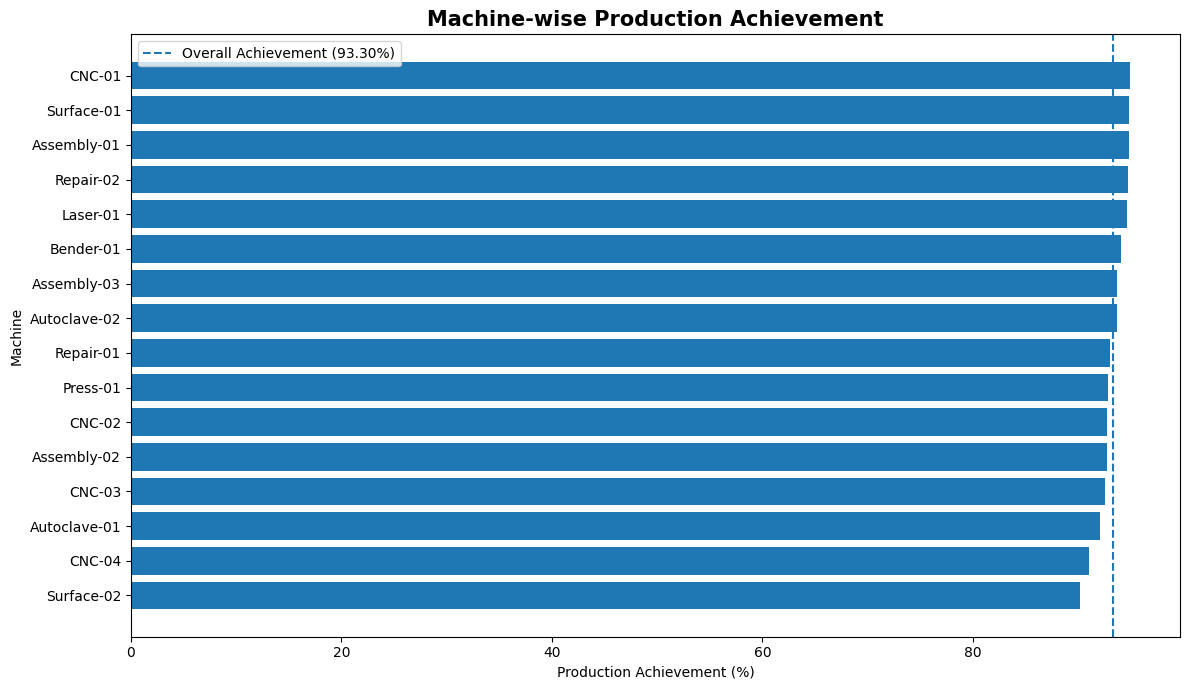

In [9]:
# Machine-wise Production Achievement Chart

import matplotlib.pyplot as plt

machine_chart = machine_analysis.sort_values(
    "Achievement_%", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    machine_chart.index,
    machine_chart["Achievement_%"]
)

plt.axvline(
    93.30,
    linestyle="--",
    label="Overall Achievement (93.30%)"
)

plt.title(
    "Machine-wise Production Achievement",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Production Achievement (%)")
plt.ylabel("Machine")

plt.legend()
plt.tight_layout()

plt.savefig(
    "../outputs/figures/machine_production_achievement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Recreate Machine-wise Downtime Analysis

machine_downtime = (
    df.groupby("Machine")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Total_Downtime=("Downtime_Hours", "sum"),
        Total_Defects=("Defects", "sum")
    )
)

machine_downtime["Downtime_per_1000_Units"] = (
    machine_downtime["Total_Downtime"]
    / machine_downtime["Total_Production"] * 1000
).round(2)

display(
    machine_downtime.sort_values(
        "Downtime_per_1000_Units",
        ascending=False
    )
)

,Total_Production,Total_Downtime,Total_Defects,Downtime_per_1000_Units
Machine,,,,
CNC-04,7695,222.6,410,28.93
Surface-01,12694,327.9,544,25.83
CNC-02,9443,240.7,379,25.49
Assembly-02,18997,482.9,875,25.42
Laser-01,10878,275.0,527,25.28
CNC-03,5953,148.0,323,24.86
Autoclave-02,16255,393.0,806,24.18
CNC-01,18723,446.1,859,23.83
Assembly-03,16307,384.3,714,23.57


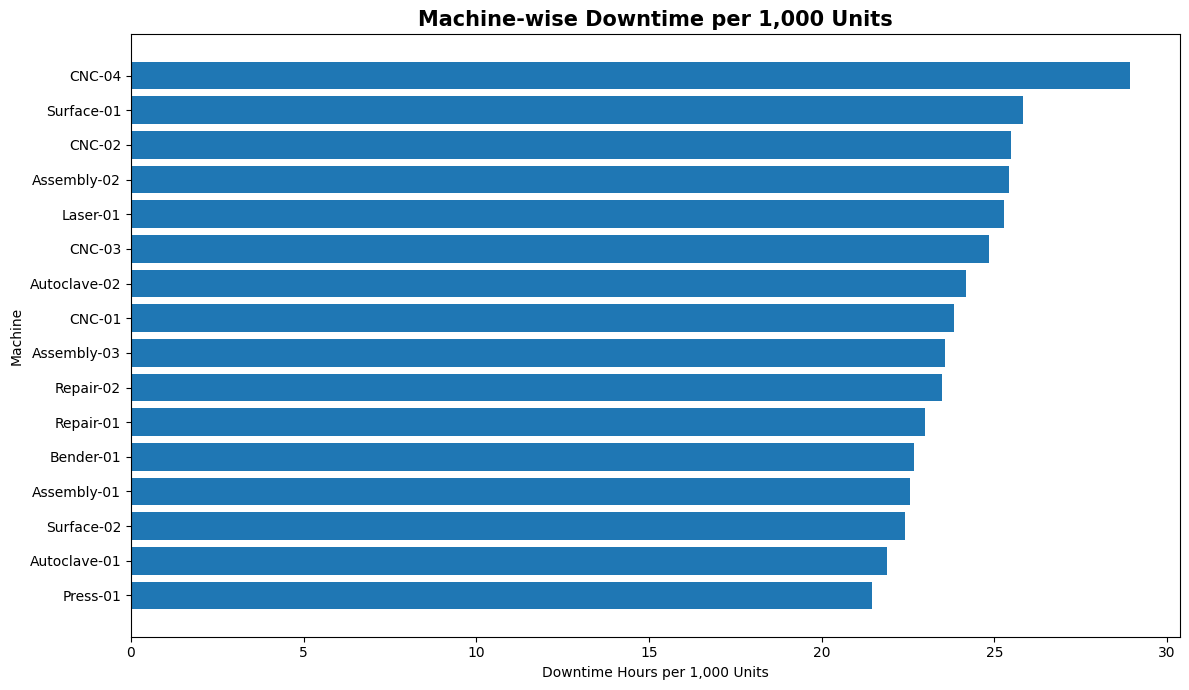

In [11]:
# Machine-wise Downtime Intensity Chart

import matplotlib.pyplot as plt

downtime_chart = machine_downtime.sort_values(
    "Downtime_per_1000_Units",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    downtime_chart.index,
    downtime_chart["Downtime_per_1000_Units"]
)

plt.title(
    "Machine-wise Downtime per 1,000 Units",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Downtime Hours per 1,000 Units")
plt.ylabel("Machine")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/machine_downtime_intensity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Recreate Department-wise Cost Analysis

cost_analysis = (
    df.groupby("Department")
    .agg(
        Total_Production=("Actual_Production", "sum"),
        Material_Cost=("Material_Cost", "sum"),
        Labour_Cost=("Labour_Cost", "sum")
    )
)

cost_analysis["Total_Cost"] = (
    cost_analysis["Material_Cost"]
    + cost_analysis["Labour_Cost"]
)

cost_analysis["Cost_per_Unit"] = (
    cost_analysis["Total_Cost"]
    / cost_analysis["Total_Production"]
).round(2)

display(
    cost_analysis.sort_values(
        "Cost_per_Unit",
        ascending=False
    )
)

,Total_Production,Material_Cost,Labour_Cost,Total_Cost,Cost_per_Unit
Department,,,,,
Composite,56256,16884044.23,37443.50,16921487.73,300.79
Machining,23091,5304981.82,15090.34,5320072.16,230.40
Assembly,51256,9557166.07,33925.06,9591091.13,187.12
Surface Treatment,26976,3897762.11,17885.28,3915647.39,145.15
Sheet Metal,30708,3583646.02,20565.26,3604211.28,117.37
Spares & Repairs,32773,3028362.30,22305.26,3050667.56,93.08


# Manufacturing Production Data Analysis

## Executive Summary

This project analyzes manufacturing production data to evaluate production performance, product quality, machine efficiency, delivery performance, downtime, and production costs.

The analysis uses **1,195 production records** covering six departments, eight product types, and sixteen machines.

### Key Performance Indicators

| KPI | Result |
|---|---:|
| Total Production Records | 1,195 |
| Total Production Target | 236,926 |
| Total Actual Production | 221,060 |
| Production Achievement | 93.30% |
| Total Defects | 10,542 |
| Overall Defect Rate | 4.77% |
| Total Downtime | 5,262.10 hours |
| On-time Delivery Rate | 61.76% |
| Late Delivery Rate | 38.24% |

### Key Business Insights

1. **Production Performance:** Overall production achievement was 93.30%. Assembly Kit Y recorded the highest product-level achievement at 94.68%.

2. **Department Performance:** Sheet Metal and Spares & Repairs achieved the highest department-level production performance at 93.77%.

3. **Product Quality:** The overall defect rate was 4.77%. Composite recorded the highest department-level defect rate at 4.99%.

4. **Shift Performance:** The Night Shift had the highest defect rate at 4.98%, while the Evening Shift had the lowest at 4.45%.

5. **Machine Performance:** CNC-01 achieved the highest production achievement at 94.92%, while Surface-02 recorded the lowest at 90.18%.

6. **Downtime Efficiency:** CNC-04 recorded the highest downtime intensity at 28.93 hours per 1,000 production units.

7. **Delivery Performance:** 61.76% of deliveries were on time. Late deliveries had an average delay of 2.37 days.

8. **Cost Analysis:** Composite had the highest calculated cost per unit at 300.79, while Spares & Repairs had the lowest at 93.08.

### Recommendations

- Investigate production gaps in departments and machines with relatively lower achievement.
- Review quality performance across shifts and departments to identify areas requiring further investigation.
- Examine downtime patterns, particularly for machines with higher downtime per 1,000 units.
- Investigate the causes of late deliveries and identify opportunities to improve delivery performance.
- Validate cost data and measurement units before making operational or financial decisions.

### Data Limitations

- Eight records have missing Operator IDs, so operator-level analysis covers 1,187 records rather than all 1,195 records.
- Six records have missing Customer values.
- Four records have an unrecorded Quality Status.
- Material Cost is substantially higher than Labour Cost. The cost fields and their units require further validation.
- Cost calculations include Material Cost and Labour Cost only; overhead and other operating expenses are excluded.

### Conclusion

This project demonstrates an end-to-end manufacturing data analysis workflow, including data preparation, exploratory analysis, KPI calculation, performance evaluation, visualization, and business insight development using Python.

The findings provide a structured overview of production, quality, delivery, machine, downtime, and cost performance.